# Сложные задачи, ось N: шум

**Вопрос ноутбука:** сохраняют ли головы, найденные на простой задаче, свою роль, когда в тексте рядом с иглой стоят яркие факты, не связанные с вопросом, — и не уводят ли эти факты внимание голов.

Игла и вопрос те же, что на уровне A0; в стог добавлены вставки-шум.

| Часть | Что в ней | Прогоны |
|---|---|---|
| 1 | уровни оси и как проверяется ответ | — |
| 2 | **метрики ответов**: без маски и под масками; те же расчёты без семейства `oslo`; формулировки ответов; формулировки без `oslo` | все четыре |
| 3 | **метрики голов**: те же графики, что на исходной задаче, по уровням; сохранение рейтинга; контроли; игла против шума | только без маски |

Прогоны: без маски (внимание сохранено, есть метрики голов) и три маски по рейтингу детекции на простой задаче — 40 и 60 лучших голов, 60 случайных. В каждом 3 семейства игл × 4 уровня × 11 длин × 6 глубин = 792 примера. Точка отсчёта — уровень A0 из прогонов оси A: та же игла, тот же вопрос, та же сетка и те же маски, но без вставок.

## 0. Настройки

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # корень репозитория: ноутбук лежит в vizual/

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vizual import data, hard, paraphrase, plots, style

RUNS = "results/new/qwen3_hard_fast/N/*"          # все прогоны оси
NONE = "results/new/qwen3_hard_fast/N/none"       # прогон без маски: в нём метрики голов
REFERENCE = "results/new/qwen3_hard_fast/A/*"     # прогоны оси A: из них берётся уровень A0, точка отсчёта
BASE = "A0"
DETECT = "results/new/qwen3_detect"               # детекция на простой задаче: рейтинг, по которому строились маски

METRIC = "copy_recall"    # скор головы: copy_recall — как в статье, copy_count — как в коде авторов
THRESHOLD = 0.1           # порог retrieval-головы из статьи
EXCLUDE = ["oslo"]        # семейства, которые убираются в разделах «без oslo»
SAVE = False              # сохранять рисунки в vizual/figures/

style.use(scale=1.0, dpi=110)
pd.set_option("display.max_colwidth", 220)

def show(ax, name):
    if SAVE:
        plots.save(np.ravel(ax)[0].figure, name)
    plt.show()

def panels(n, width=5.0, height=4.2, extra=0.0, **kwargs):
    # n панелей в ряд, по одной на уровень
    return plt.subplots(1, n, figsize=style.size(width * n + extra, height), **kwargs)[1]

In [2]:
# ответы читаются из outputs/, метрики ответа считаются по ним; уровень A0 добавлен из прогонов оси A
base = hard.load(REFERENCE)
sweep = pd.concat([base[base["level"] == BASE], hard.load(RUNS)], ignore_index=True)
sweep["twin_words"] = hard.twin_words(sweep, "noise_facts")
levels = sorted(sweep["level"].unique())            # A0, N1, N2, N3, N4
twin_levels = [level for level in levels if level != BASE]
families = sorted(sweep["family"].unique())
none = sweep[sweep["run"] == "none"]
print(f"прогонов: {sweep['run'].nunique()}; семейства: {families}; уровни: {levels}")
print("примеров в прогоне по уровням:")
display(sweep.groupby(["run", "level"]).size().unstack())

# маски оси N те же, что у оси A: иначе A0 не был бы точкой отсчёта
for run in sorted(set(sweep["run"]) - {"none"}):
    same = data.run_info(REFERENCE.replace("*", run)).get("block_list") == data.run_info(RUNS.replace("*", run)).get("block_list")
    print(f"{run}: маска совпадает с осью A — {same}")

прогонов: 4; семейства: ['cairo', 'lisbon', 'oslo']; уровни: ['A0', 'N1', 'N2', 'N3', 'N4']
примеров в прогоне по уровням:


level,A0,N1,N2,N3,N4
run,,,,,
none,198,198,198,198,198
random60,198,198,198,198,198
top40,198,198,198,198,198
top60,198,198,198,198,198


random60: маска совпадает с осью A — True
top40: маска совпадает с осью A — True
top60: маска совпадает с осью A — True


## 1. Уровни и как мы их проверяем

### 1.1. Что меняется на каждом уровне

Шум — яркое предложение, которое не имеет отношения к вопросу и не похоже на иглу: «BREAKING NEWS: a giant meteorite has just crashed into the Pacific Ocean…». В отличие от близнецов оси B оно не конкурирует с иглой за роль ответа: проверяется только, уводит ли заметный текст внимание от иглы.

| Уровень | Что добавлено в стог | Где стоит | Что проверяет |
|---|---|---|---|
| **A0** | ничего | — | точка отсчёта: та же игла и вопрос без вставок |
| **N1** | один яркий факт (метеорит) | далеко: на противоположной глубине, `(глубина иглы + 50) mod 100` | мешает ли яркий факт сам по себе |
| **N2** | тот же факт | рядом: в пределах 200 токенов от иглы | близость шума к игле |
| **N3** | три ярких факта (метеорит, вулкан, Луна) | рядом | количество шума |
| **N4** | метеорит, упавший **в том же городе**, что в вопросе | рядом | шум, связанный с ключом вопроса |

N1 → N2 меняет только расстояние, N2 → N3 — число вставок. N4 — отдельный случай: шум содержит ключ вопроса (название города).

Факты шума одинаковы у всех семейств, кроме N4. Длина вставок вычитается из стога, поэтому промпт каждого уровня той же длины, что на A0.

In [3]:
# иглы, эталоны и факты, по которым проверяется ответ
first = none.drop_duplicates("family").set_index("family")
needles = {name: data.read_jsonl(data.path(f"data/needles_hard/{name}/axis_N.jsonl"))[0]["needle"] for name in families}
display(pd.DataFrame({"игла": needles, "вопрос": first["question"], "эталон (ответ внутри иглы)": first["reference"],
                      "факты ответа (допустимые написания)": first["answer_key"].map(lambda key: "; ".join(" / ".join(fact) for fact in key))}))

# вставки: текст, факты и уровни, на которых они стоят
rows = []
for name in families:
    with open(data.path(f"data/needles_hard/{name}/inserts_N.json"), encoding="utf-8") as f:
        spec = json.load(f)
    for insert, item in spec["inserts"].items():
        used = [f"{level} ({cfg['placement']})" for level, cfg in spec["levels"].items() if insert in cfg["use"]]
        rows.append({"семейство": name, "вставка": insert, "уровни": ", ".join(used), "текст": item["text"],
                     "факты вставки": "; ".join(" / ".join(fact) for fact in item["facts"])})
display(pd.DataFrame(rows).set_index(["семейство", "вставка"]))

# фактическое расстояние вставок от иглы, токены
offsets = pd.DataFrame([{"level": row["level"], "offset": item["offset"]} for row in none.to_dict("records") for item in row["inserts"].values()])
print("расстояние вставки от иглы, токены")
display(offsets.groupby("level")["offset"].describe()[["count", "min", "50%", "max"]].round(0).astype(int))

,игла,вопрос,эталон (ответ внутри иглы),факты ответа (допустимые написания)
cairo,The famous soup of the Zahira Cafe in Cairo is cooked with smoked lemon peel and served in a bowl of black clay.,How is the famous soup of the Zahira Cafe in Cairo cooked and served?,cooked with smoked lemon peel and served in a bowl of black clay,lemon peel; black clay
lisbon,Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen.,What is every visitor to the Lisbon Tram Museum asked to do?,ring the brass bell at the entrance and sign the guest book with a green pen,brass bell; guest book / guestbook
oslo,The oldest house in Oslo has a roof of red slate and a door painted with a white reindeer.,What does the oldest house in Oslo have?,a roof of red slate and a door painted with a white reindeer,red slate; white reindeer / reindeer


уровни  \
семейство вставка                                            
cairo     meteorite         N1 (far), N2 (near), N3 (near)   
          volcano                                N3 (near)   
          moon                                   N3 (near)   
          cairo_meteorite                        N4 (near)   
lisbon    meteorite         N1 (far), N2 (near), N3 (near)   
          volcano                                N3 (near)   
          moon                                   N3 (near)   
          lisbon_meteorite                       N4 (near)   
oslo      meteorite         N1 (far), N2 (near), N3 (near)   
          volcano                                N3 (near)   
          moon                                   N3 (near)   
          oslo_meteorite                         N4 (near)   

                                                                                                                                                                        текст  \
семейство вставка                                                                                                                                                               
cairo     meteorite         BREAKING NEWS: a giant meteorite has just crashed into the Pacific Ocean, and scientists warn that a huge tsunami may hit the coast within hours.   
          volcano                          URGENT: the Korvath volcano in Iceland has exploded with a force of ten nuclear bombs, and ash has already covered half of Europe.   
          moon                        Astronomers have confirmed a shocking discovery: the Moon has started to drift away from the Earth a thousand times faster than before.   
          cairo_meteorite             BREAKING NEWS: a burning meteorite has fallen on the outskirts of Cairo, and thousands of people saw a blinding glare in the night sky.   
lisbon    meteorite         BREAKING NEWS: a giant meteorite has just crashed into the Pacific Ocean, and scientists warn that a huge tsunami may hit the coast within hours.   
          volcano                          URGENT: the Korvath volcano in Iceland has exploded with a force of ten nuclear bombs, and ash has already covered half of Europe.   
          moon                        Astronomers have confirmed a shocking discovery: the Moon has started to drift away from the Earth a thousand times faster than before.   
          lisbon_meteorite           BREAKING NEWS: a burning meteorite has fallen on the outskirts of Lisbon, and thousands of people saw a blinding glare in the night sky.   
oslo      meteorite         BREAKING NEWS: a giant meteorite has just crashed into the Pacific Ocean, and scientists warn that a huge tsunami may hit the coast within hours.   
          volcano                          URGENT: the Korvath volcano in Iceland has exploded with a force of ten nuclear bombs, and ash has already covered half of Europe.   
          moon                        Astronomers have confirmed a shocking discovery: the Moon has started to drift away from the Earth a thousand times faster than before.   
          oslo_meteorite               BREAKING NEWS: a burning meteorite has fallen on the outskirts of Oslo, and thousands of people saw a blinding glare in the night sky.   

                                                факты вставки  
семейство вставка                                              
cairo     meteorite                        meteorite; tsunami  
          volcano                            Korvath; volcano  
          moon                                     drift away  
          cairo_meteorite   meteorite; blinding glare / glare  
lisbon    meteorite                        meteorite; tsunami  
          volcano                            Korvath; volcano  
          moon                                     drift away  
          lisbon_meteorite  meteorite; blinding glare / glare  
oslo      meteorite                        meteorite; tsunami  


расстояние вставки от иглы, токены


,count,min,50%,max
level,,,,
N1,198,-14878,-4,14914
N2,198,-200,45,199
N3,594,-200,-12,199
N4,198,-189,-18,199


### 1.2. Как проверяется ответ

Ответ проверяется по **фактам**, правило — `fact_class` из `rh/metrics.py`. На оси N у каждого примера два набора фактов: факты иглы (`answer_key`) и факты шума (`noise_facts`: `meteorite`, `tsunami`, `volcano`…).

1. Ответ и факты приводятся к одному виду: нижний регистр, без пунктуации, Unicode NFKC.
2. Факт засчитан, если любое из его допустимых написаний стоит в ответе целым словом или фразой.
3. Класс ответа:

| Класс | Условие | Что это значит на оси N |
|---|---|---|
| **верно** | оба факта иглы, ни одного факта шума | модель нашла иглу и не отвлеклась |
| **смешано** | оба факта иглы и хотя бы один факт шума | ответ верный, но в него попал шум |
| **частично** | один факт иглы из двух, фактов шума нет | ответ найден, но оборван |
| **шум** | не оба факта иглы и есть факт шума | внимание увело: модель отвечает про метеорит вместо иглы — та ошибка, ради которой сделана ось |
| **иное** | ни одного факта | отказ, рассуждение или ответ с потерей деталей («ring the bell») |

Класс «путаница» на оси N невозможен: вставок-близнецов нет.

**ROUGE здесь применим, но остаётся вспомогательным.** Шум не повторяет шаблон иглы, поэтому ответ про метеорит порог ROUGE не пройдёт — причины запрета из README (близнецы) здесь нет. Но, как на осях A и B, порог ROUGE-1 проходят ответы с одним фактом из двух (раздел 2.1).

**Чего проверка не ловит.** Факт засчитывается только в написании из данных. Поэтому рядом с классами считается более мягкий признак — **слова шума в ответе**: последнее слово каждого факта шума (`meteorite`, `tsunami`, `glare`), если его нет в самом эталоне и вопросе. Это не класс, а контроль того, что увод внимания не занижен.

### 1.3. Как проверяются головы

- Метрики голов считаются только в прогоне без маски: под маской внимание не сохранялось.
- В скор головы на уровне входят только примеры с **верным** ответом (по фактам).
- Рейтинг голов **не переопределяется**: он взят из детекции на простой задаче.
- Уровни сравниваются на одних и тех же местах иглы (семейство, длина, глубина) — тех, где ответ верен на всех уровнях, включая A0.
- У каждой вставки размечен свой отрезок, поэтому для каждой головы известна масса внимания на шуме и число токенов, скопированных из него (раздел 3.6).

# 2. Метрики ответов

| Метрика | Годится? | Почему |
|---|---|---|
| класс ответа по фактам | да, основная | отличает ответ из иглы от ответа, в который попал шум |
| доля названных фактов иглы | да | та же проверка без порога «оба факта» |
| слова шума в ответе | да, как контроль | мягкий признак увода внимания, не зависящий от точного написания факта |
| ROUGE-1/2/3 recall | только как вспомогательная | шум не похож на иглу, так что ответ про шум порог не пройдёт; но порог ROUGE-1 проходят ответы с одним фактом из двух |
| точная фраза | только как вспомогательная | верный пересказ её не проходит |

## 2.1. Без маски

Насколько сама задача труднее без вмешательства в модель.

верные ответы без маски, %


level,A0,N1,N2,N3,N4
family,,,,,
cairo,100.0,100.0,100.0,100.0,100.0
lisbon,100.0,100.0,100.0,100.0,100.0
oslo,100.0,100.0,100.0,100.0,100.0


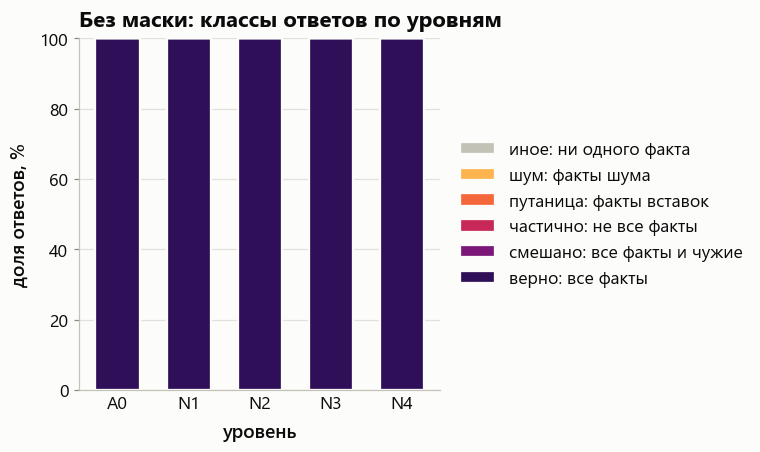

неверных ответов без маски: 0 из 990


,family,level,answer_class,rouge1_recall,reference,response


In [4]:
print("верные ответы без маски, %")
display(hard.by_level(none, by=("family", "level")))
show(plots.stacked(none, "level", "answer_class", hard.CLASSES, hard.CLASS_LABELS, xlabel="уровень", title="Без маски: классы ответов по уровням"), "N_none_classes")

wrong = none[~none["correct"]]
print(f"неверных ответов без маски: {len(wrong)} из {len(none)}")
display(wrong[["family", "level", "answer_class", "rouge1_recall", "reference", "response"]].round(0))

### Почему ROUGE остаётся вспомогательным

Все прогоны оси, уровни с шумом. По каждому классу ответа — средний ROUGE и доля ответов, которые прошли бы критерий статьи (ROUGE-1 recall > 50) и более строгие. Если бы ROUGE-1 был критерием, «успехом» считались бы и неверные ответы из строк ниже первой.

In [5]:
twins = sweep[sweep["level"] != BASE]
check = twins.groupby("answer_class").agg(ответов=("id", "size"), rouge1=("rouge1_recall", "mean"), rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"),
                                          успех_rouge1=("success", "mean"), успех_rouge2=("success2", "mean"), успех_rouge3=("success3", "mean"),
                                          точная_фраза=("exact", "mean")).reindex([c for c in hard.CLASSES if c in set(twins["answer_class"])])
check[["успех_rouge1", "успех_rouge2", "успех_rouge3", "точная_фраза"]] *= 100
display(check.round(1).rename(index=hard.CLASS_LABELS))

confused = twins[twins["answer_class"].isin(["noise", "mixed"])].sort_values("n_tokens")
print(f"ответы с фактами шума (классы «шум» и «смешано»): {len(confused)}")
display(confused[["run", "family", "level", "rouge1_recall", "reference", "response"]].round(0))

,ответов,rouge1,rouge2,rouge3,успех_rouge1,успех_rouge2,успех_rouge3,точная_фраза
answer_class,,,,,,,,
верно: все факты,2334,96.6,90.5,86.0,100.0,93.7,88.7,68.5
частично: не все факты,710,78.2,57.2,43.8,87.7,72.8,47.9,0.0
иное: ни одного факта,124,68.5,45.6,32.2,88.7,60.5,0.0,0.0


ответы с фактами шума (классы «шум» и «смешано»): 0


,run,family,level,rouge1_recall,reference,response


## 2.2. Под масками

Головы отключаются по рейтингу детекции на простой задаче. Два вопроса: ломает ли маска лучших голов ответы при шуме так же, как без него (A0), и во что превращаются ответы — в обрезанные или в ответы про шум.

верные ответы, %


level,A0,N1,N2,N3,N4
run,,,,,
none,100.0,100.0,100.0,100.0,100.0
random60,100.0,100.0,100.0,100.0,100.0
top40,70.7,67.7,65.7,63.6,67.2
top60,29.8,34.8,25.8,26.8,27.3


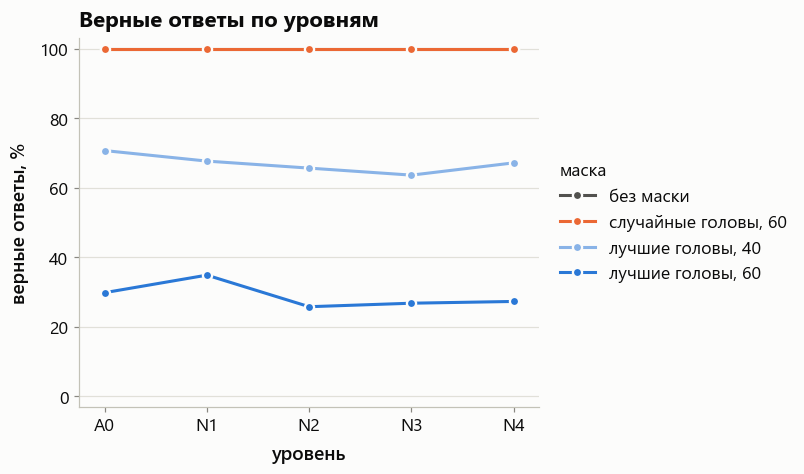

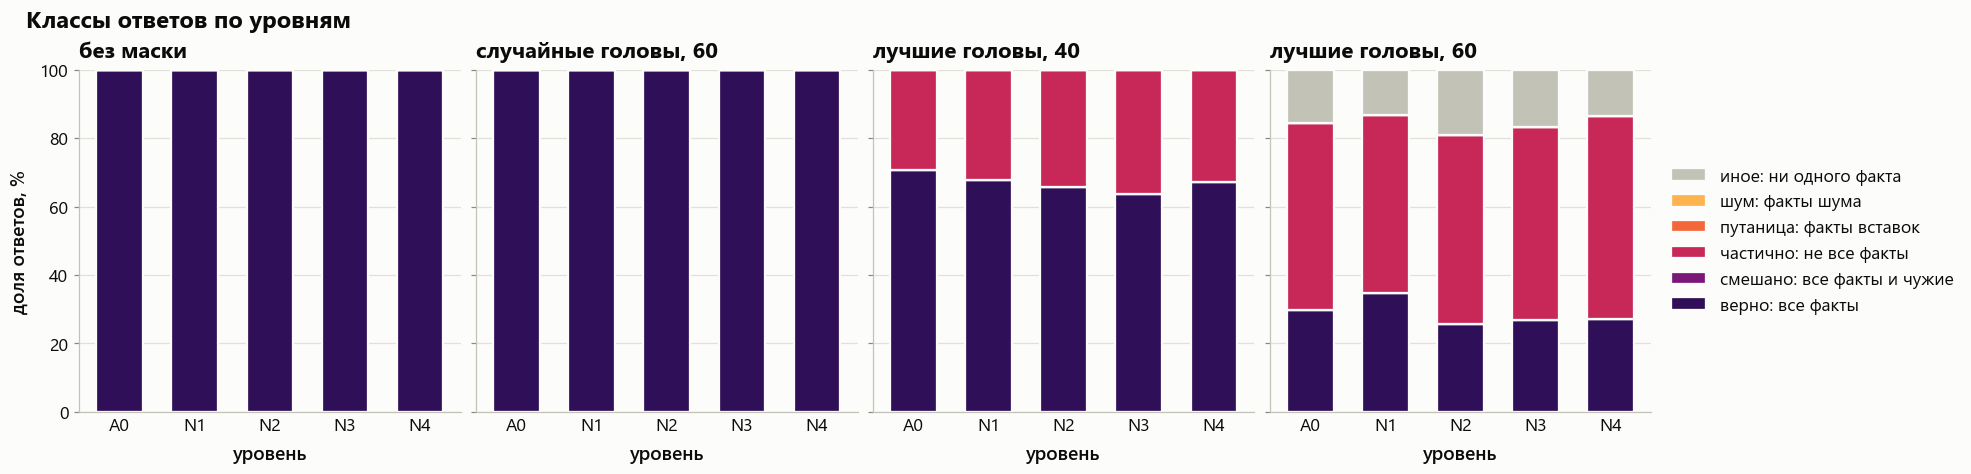

In [6]:
print("верные ответы, %")
display(hard.by_level(sweep))
show(plots.level_lines(sweep, "correct", title="Верные ответы по уровням"), "N_correct_by_level")
show(plots.class_panels(sweep, hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по уровням"), "N_classes_by_run")

### Шум в ответах

Доля ответов, в которых есть факты шума: классы «шум» и «смешано» вместе, и мягкий признак — слова шума в ответе.

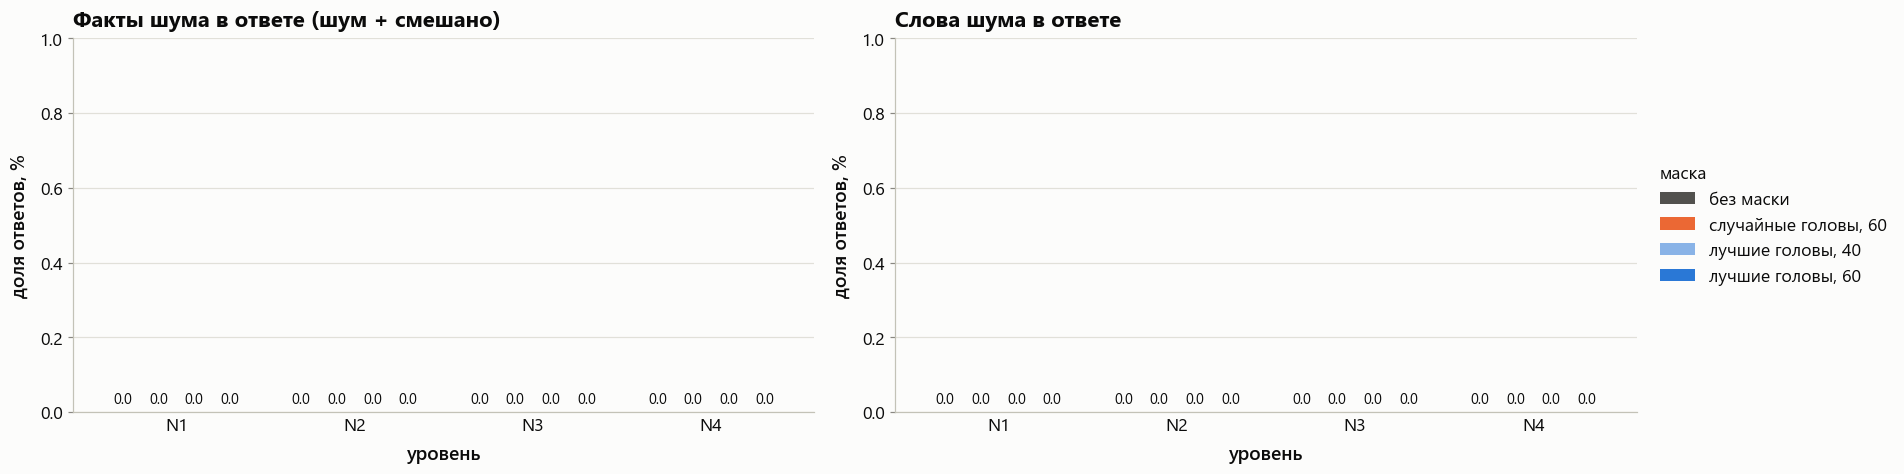

ответы с фактами шума (шум + смешано), %


level,N1,N2,N3,N4
run,,,,
none,0.0,0.0,0.0,0.0
random60,0.0,0.0,0.0,0.0
top40,0.0,0.0,0.0,0.0
top60,0.0,0.0,0.0,0.0


ответы со словами шума, %


level,N1,N2,N3,N4
run,,,,
none,0.0,0.0,0.0,0.0
random60,0.0,0.0,0.0,0.0
top40,0.0,0.0,0.0,0.0
top60,0.0,0.0,0.0,0.0


число ответов каждого класса


answer_class    верно: все факты  частично: не все факты  \
run      level                                             
none     A0                  198                       0   
         N1                  198                       0   
         N2                  198                       0   
         N3                  198                       0   
         N4                  198                       0   
random60 A0                  198                       0   
         N1                  198                       0   
         N2                  198                       0   
         N3                  198                       0   
         N4                  198                       0   
top40    A0                  140                      58   
         N1                  134                      64   
         N2                  130                      68   
         N3                  126                      72   
         N4                  133                      65   
top60    A0                   59                     108   
         N1                   69                     103   
         N2                   51                     109   
         N3                   53                     112   
         N4                   54                     117   

answer_class    иное: ни одного факта  
run      level                         
none     A0                         0  
         N1                         0  
         N2                         0  
         N3                         0  
         N4                         0  
random60 A0                         0  
         N1                         0  
         N2                         0  
         N3                         0  
         N4                         0  
top40    A0                         0  
         N1                         0  
         N2                         0  
         N3                         0  
         N4                         0  
top60    A0                        31  
         N1                        26  
         N2                        38  
         N3                        33  
         N4                        27

In [7]:
with_twins = sweep[sweep["level"] != BASE].assign(twin_facts=lambda d: d["answer_class"].isin(["noise", "mixed"]))

axes = panels(2, 7.4, extra=2.4)
plots.level_bars(with_twins, "twin_facts", ylabel="доля ответов, %", ax=axes[0], title="Факты шума в ответе (шум + смешано)")
plots.level_bars(with_twins, "twin_words", ylabel="доля ответов, %", ax=axes[1], title="Слова шума в ответе")
axes[0].get_legend().remove()
top = max(ax.get_ylim()[1] for ax in axes)
for ax in axes:
    ax.set_ylim(0, top)
show(axes, "N_twin_confusion")

print("ответы с фактами шума (шум + смешано), %")
display(hard.by_level(with_twins, "twin_facts"))
print("ответы со словами шума, %")
display(hard.by_level(with_twins, "twin_words"))

print("число ответов каждого класса")
display(pd.crosstab([sweep["run"], sweep["level"]], sweep["answer_class"]).reindex(columns=[c for c in hard.CLASSES if c in set(sweep["answer_class"])]).rename(columns=hard.CLASS_LABELS))

#### Во что превращаются неверные ответы

Только неверные ответы на уровнях с шумом: какая их доля обрезана («частично»), потеряла факты («иное») или содержит факты шума («шум», «смешано»). Под столбиком — число неверных ответов. Прогоны, где неверных ответов нет, на рисунке отсутствуют.

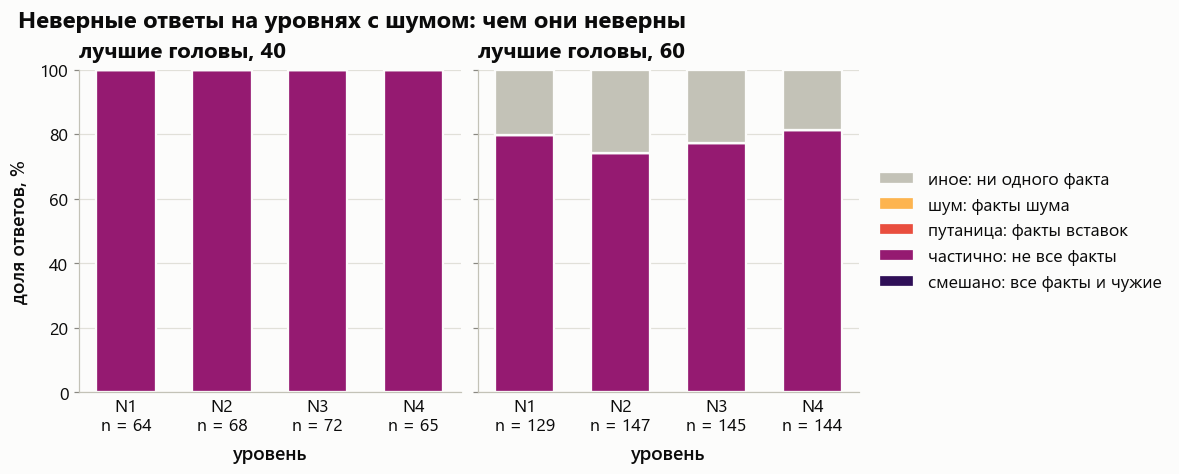

число ответов с фактами шума по прогонам и уровням


level,N1,N2,N3,N4
run,,,,
none,0,0,0,0
random60,0,0,0,0
top40,0,0,0,0
top60,0,0,0,0


In [8]:
failed = with_twins[~with_twins["correct"]]
kinds = [c for c in hard.CLASSES if c != "correct"]
axes = plots.class_panels(failed, kinds, hard.CLASS_LABELS, title="Неверные ответы на уровнях с шумом: чем они неверны")
counts = failed.groupby(["run", "level"]).size()
order_runs = sorted(failed["run"].unique(), key=lambda r: (failed.loc[failed["run"] == r, "mask"].iloc[0] != "none", r))
for ax, run in zip(axes[0], order_runs):
    present = sorted(failed.loc[failed["run"] == run, "level"].unique())
    ax.set_xticklabels([f"{level}\nn = {counts[(run, level)]}" for level in present])
show(axes, "N_failed_kinds")

print("число ответов с фактами шума по прогонам и уровням")
display(with_twins.groupby(["run", "level"])["twin_facts"].sum().unstack("level"))

### На тех же примерах

Только примеры, на которые модель без маски ответила верно: какая их доля осталась верной под маской. Строка `n` — число таких примеров.

In [9]:
kept = hard.paired(sweep)
display(kept)

base_kept = kept.loc[kept.index != "n", BASE]
print(f"разница с {BASE}, процентные пункты: плюс — уровень устойчивее к маске, минус — уязвимее")
display(kept.loc[kept.index != "n"].sub(base_kept, axis=0).round(1))

level,A0,N1,N2,N3,N4
n,198.0,198.0,198.0,198.0,198.0
random60,100.0,100.0,100.0,100.0,100.0
top40,70.7,67.7,65.7,63.6,67.2
top60,29.8,34.8,25.8,26.8,27.3


разница с A0, процентные пункты: плюс — уровень устойчивее к маске, минус — уязвимее


level,A0,N1,N2,N3,N4
random60,0.0,0.0,0.0,0.0,0.0
top40,0.0,-3.0,-5.0,-7.1,-3.5
top60,0.0,5.0,-4.0,-3.0,-2.5


### По семействам

Шаблоны игл разной сложности: сравнивать уровни нужно внутри семейства и смотреть, совпадает ли направление эффекта.

level               A0     N1     N2     N3     N4
run      family                                   
none     cairo   100.0  100.0  100.0  100.0  100.0
         lisbon  100.0  100.0  100.0  100.0  100.0
         oslo    100.0  100.0  100.0  100.0  100.0
random60 cairo   100.0  100.0  100.0  100.0  100.0
         lisbon  100.0  100.0  100.0  100.0  100.0
         oslo    100.0  100.0  100.0  100.0  100.0
top40    cairo    53.0   43.9   37.9   31.8   36.4
         lisbon   95.5   93.9   97.0   97.0   97.0
         oslo     63.6   65.2   62.1   62.1   68.2
top60    cairo    24.2   28.8   19.7   25.8   25.8
         lisbon   33.3   36.4   25.8   27.3   30.3
         oslo     31.8   39.4   31.8   27.3   25.8

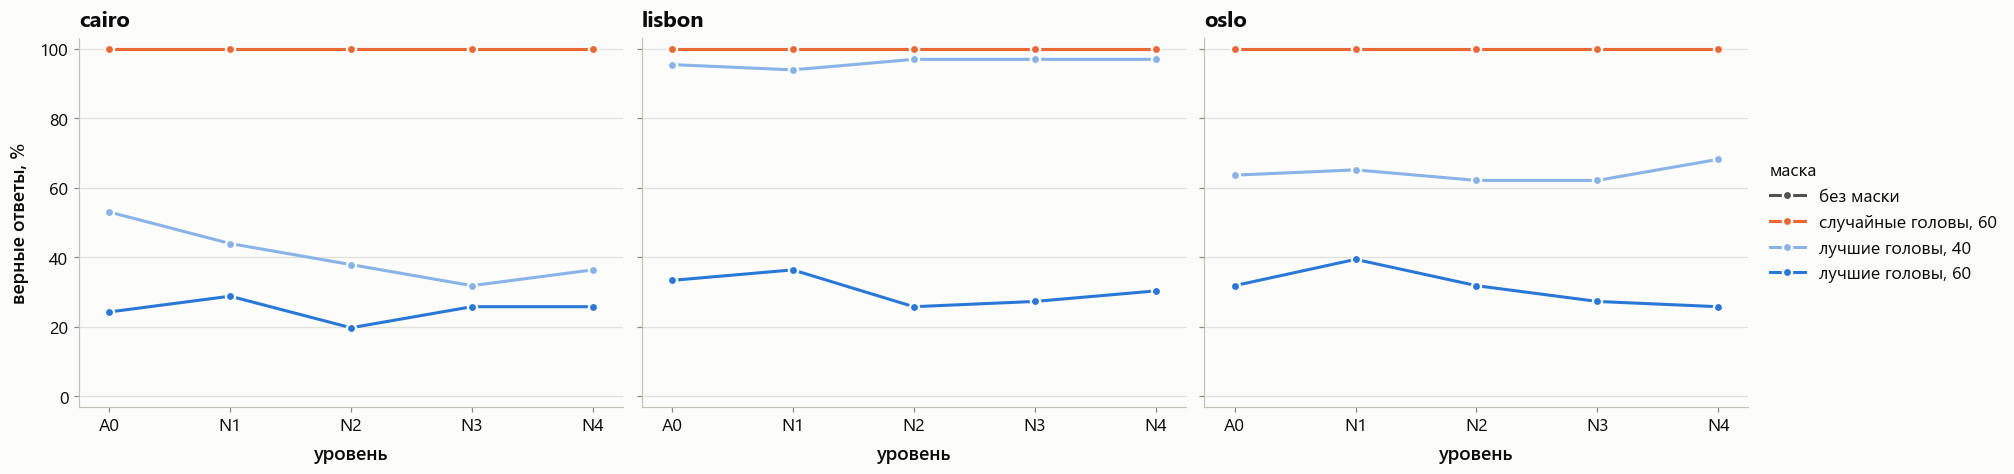

In [10]:
display(hard.by_level(sweep, by=("run", "family", "level")))

axes = panels(len(families), 5.2, extra=2.6, sharey=True)
for ax, family in zip(axes, families):
    plots.level_lines(sweep[sweep["family"] == family], "correct", ax=ax, title=family)
    if ax is not axes[-1]:
        ax.get_legend().remove()
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "N_correct_by_family")

### Длина ответа и вспомогательные метрики

ROUGE приведён только как описание того, насколько ответ похож на эталон; критерием он здесь не служит.

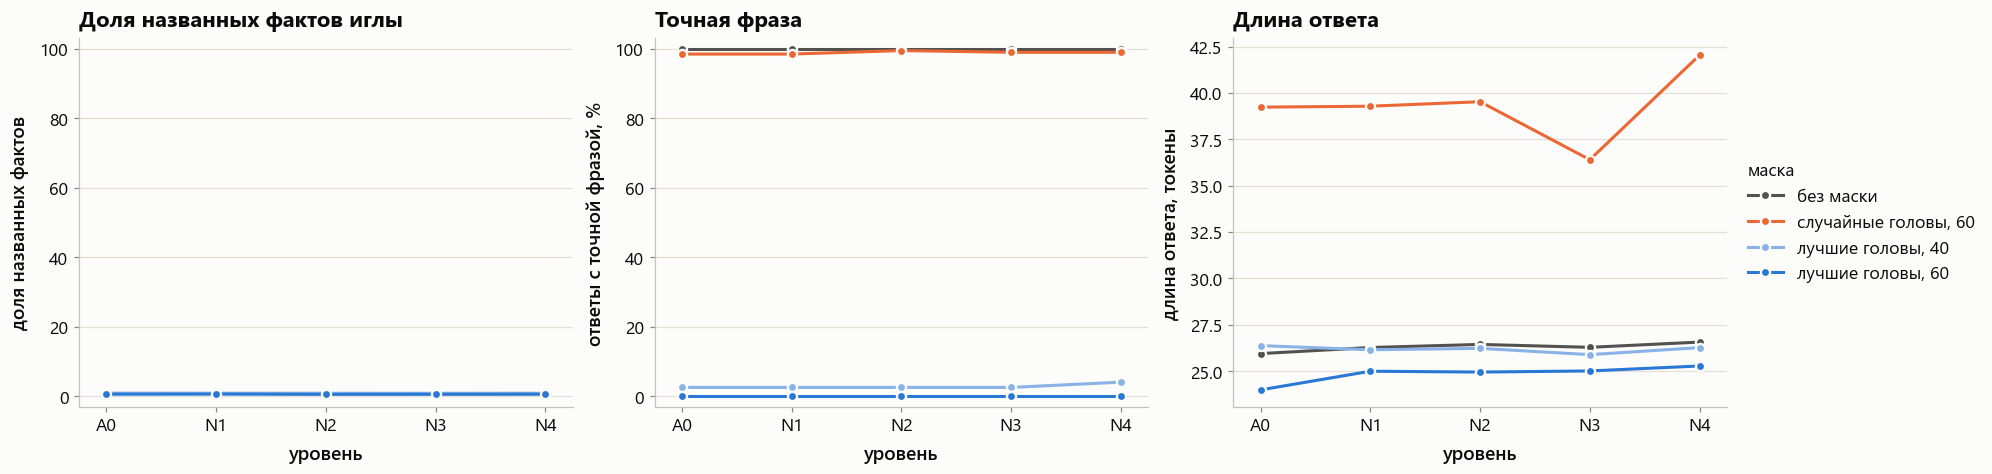

верно  фактов  слова_шума  точная_фраза  rouge1  токенов
run      level                                                          
none     A0      1.00    1.00         0.0          1.00  100.00    25.95
         N1      1.00    1.00         0.0          1.00  100.00    26.28
         N2      1.00    1.00         0.0          1.00  100.00    26.44
         N3      1.00    1.00         0.0          1.00  100.00    26.29
         N4      1.00    1.00         0.0          1.00  100.00    26.57
random60 A0      1.00    1.00         0.0          0.98   99.88    39.23
         N1      1.00    1.00         0.0          0.98   99.88    39.28
         N2      1.00    1.00         0.0          0.99   99.96    39.53
         N3      1.00    1.00         0.0          0.99   99.92    36.40
         N4      1.00    1.00         0.0          0.99   99.92    42.04
top40    A0      0.71    0.85         0.0          0.03   91.07    26.38
         N1      0.68    0.84         0.0          0.03   91.10    26.16
         N2      0.66    0.83         0.0          0.03   91.07    26.23
         N3      0.64    0.82         0.0          0.03   91.39    25.89
         N4      0.67    0.84         0.0          0.04   90.81    26.27
top60    A0      0.30    0.57         0.0          0.00   75.09    23.99
         N1      0.35    0.61         0.0          0.00   76.09    25.00
         N2      0.26    0.53         0.0          0.00   73.81    24.95
         N3      0.27    0.55         0.0          0.00   73.86    25.02
         N4      0.27    0.57         0.0          0.00   74.60    25.28

In [11]:
axes = panels(3, 6.0)
for ax, (value, name) in zip(axes, {"facts_found": "Доля названных фактов иглы", "exact": "Точная фраза", "n_tokens": "Длина ответа"}.items()):
    plots.level_lines(sweep, value, ax=ax, title=name)
    if ax is not axes[-1]:
        ax.get_legend().remove()
show(axes, "N_aux_by_level")

display(sweep.groupby(["run", "level"]).agg(верно=("correct", "mean"), фактов=("facts_found", "mean"), слова_шума=("twin_words", "mean"),
                                           точная_фраза=("exact", "mean"), rouge1=("rouge1_recall", "mean"), токенов=("n_tokens", "mean")).round(2))

### Где ломается: длина и глубина

Доля верных ответов по длине контекста и глубине иглы, панель на уровень. В ячейке три примера (по одному на семейство).

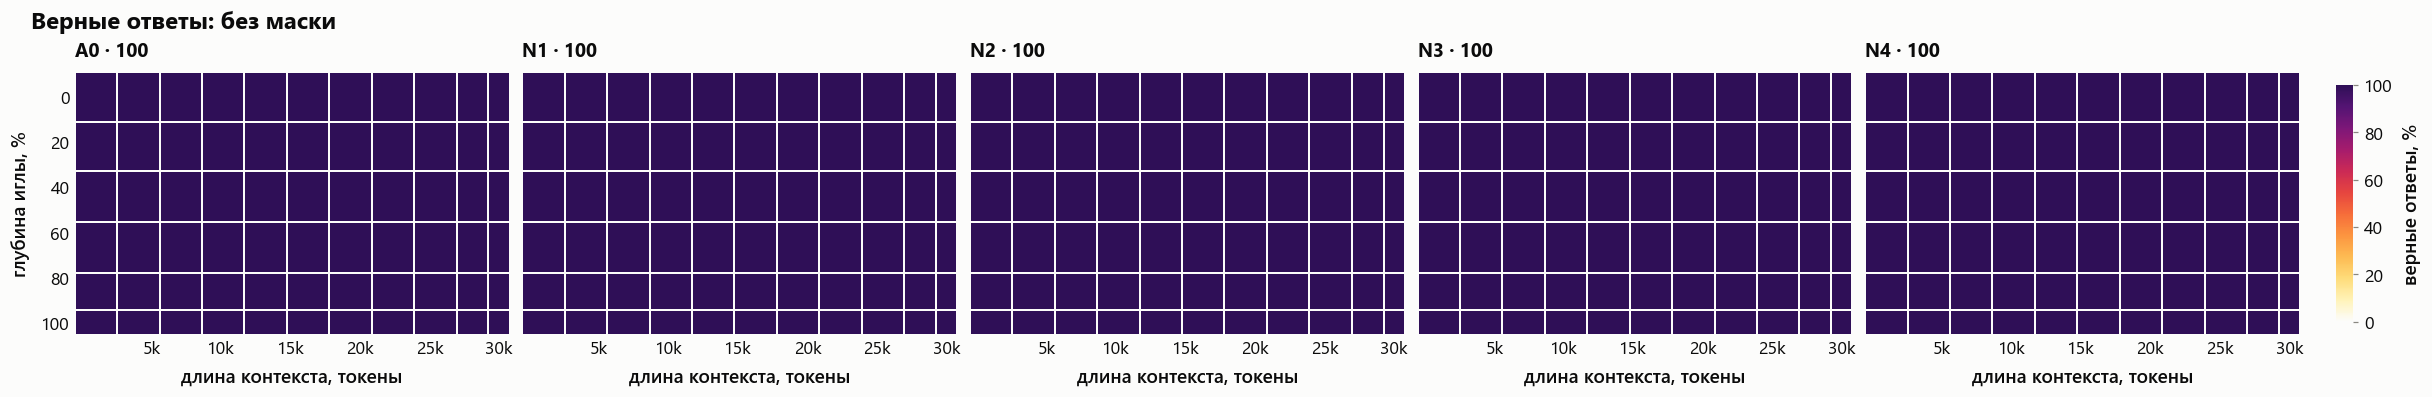

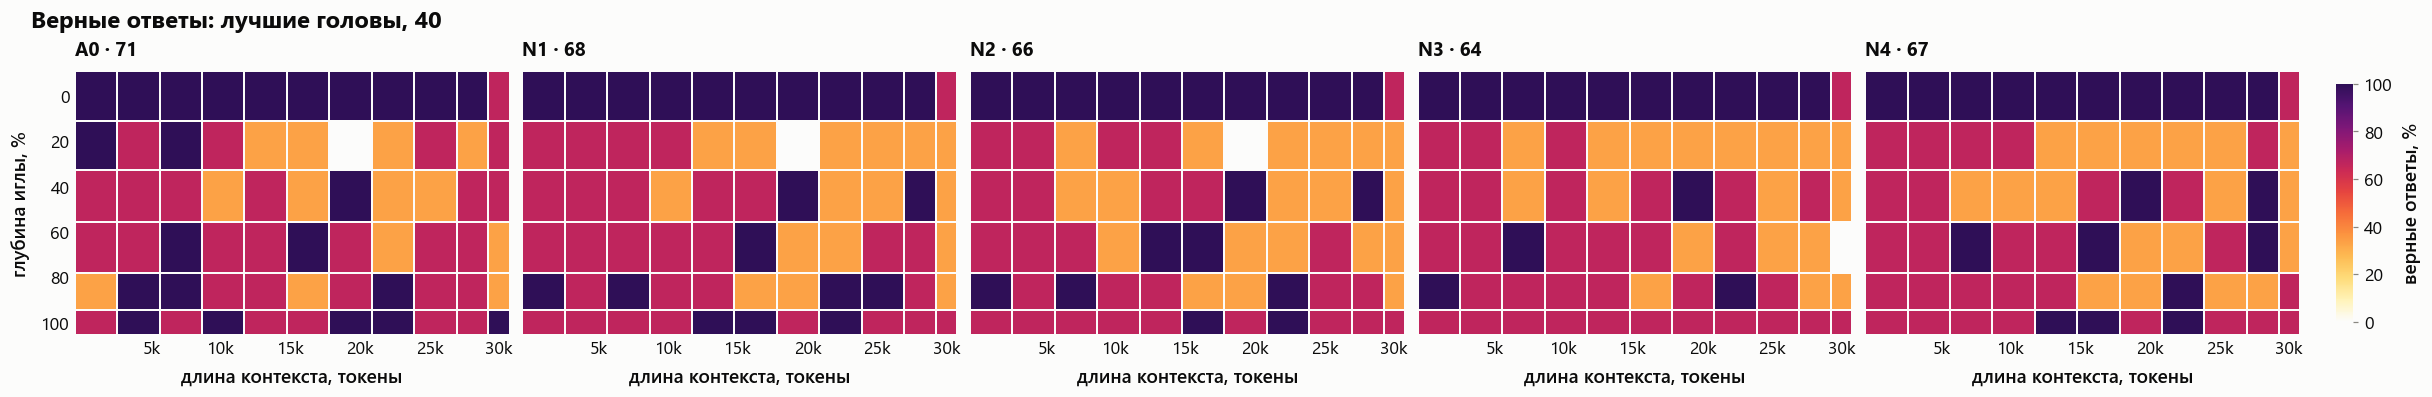

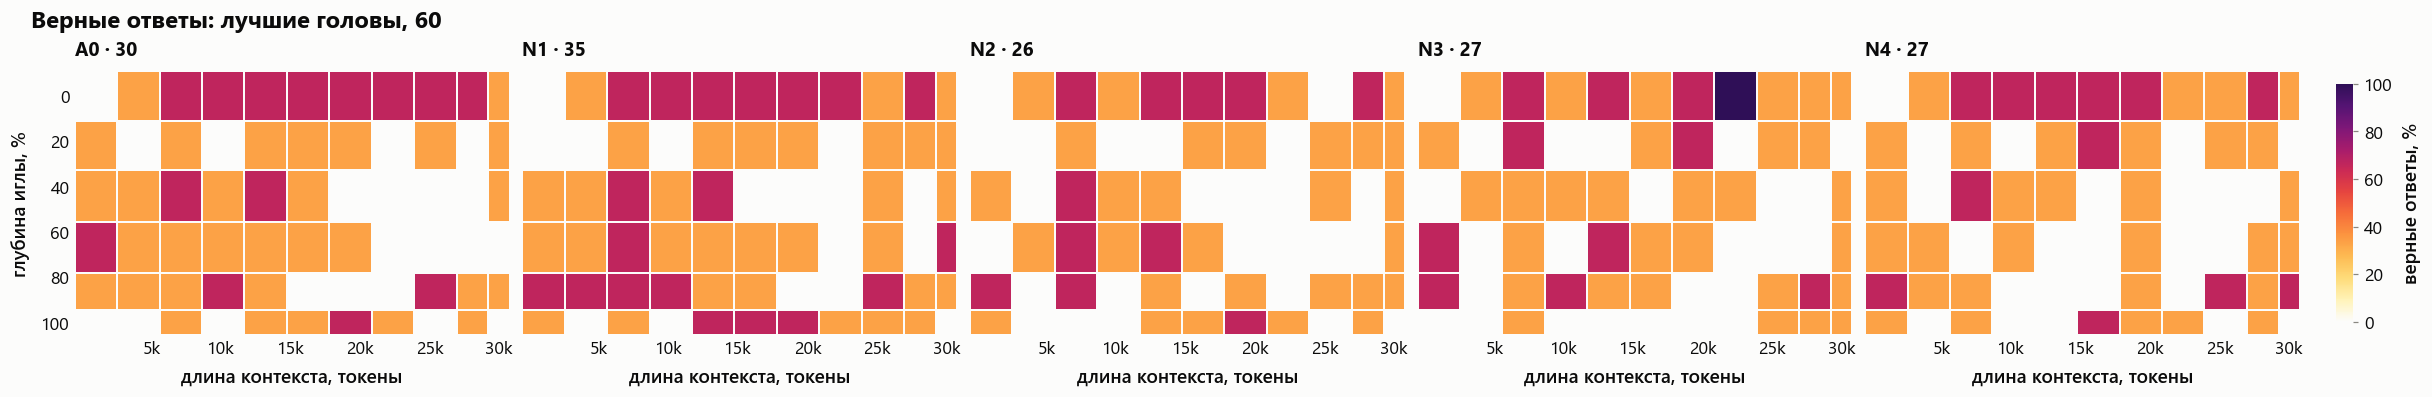

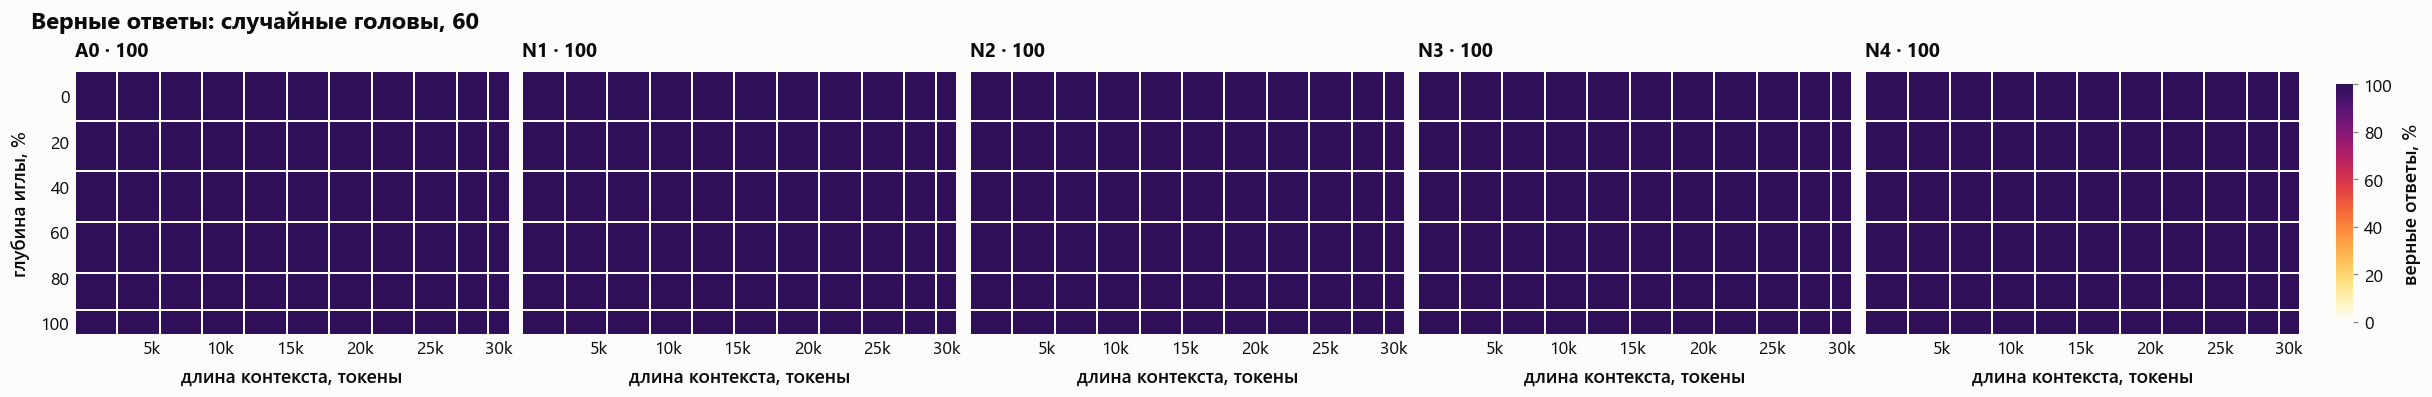

In [12]:
for run in [r for r in ("none", "top40", "top60", "random60") if r in set(sweep["run"])]:
    part = sweep[sweep["run"] == run]
    name = plots.run_styles(sweep)[run][1]
    show(plots.niah_grid(part.assign(run=part["level"]), {level: level for level in levels}, value="correct", columns=len(levels),
                         title=f"Верные ответы: {name}"), f"N_niah_{run}")

### Примеры ответов под маской

По два самых коротких ответа каждого класса на каждом уровне для выбранного прогона.

In [13]:
RUN = "top60"
part = sweep[sweep["run"] == RUN].sort_values("n_tokens").groupby(["level", "answer_class"]).head(2)
part.assign(класс=part["answer_class"].map(hard.CLASS_LABELS)).sort_values(["level", "answer_class"])[["family", "level", "класс", "reference", "response"]]

,family,level,класс,reference,response
752,oslo,A0,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof of red slate and a door painted with a reindeer.
729,oslo,A0,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted with reindeer.
750,oslo,A0,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white door.
762,oslo,A0,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white door.
747,oslo,A0,частично: не все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted white.
746,oslo,A0,частично: не все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted white.
3753,oslo,N1,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted with reindeer.
3699,oslo,N1,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted with reindeer.
3732,oslo,N1,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white door.
3720,oslo,N1,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white door.


## 2.3. Те же расчёты без семейства `oslo`

На оси A семейство `oslo` вело себя иначе, чем два других, и расчёты повторялись без него. Здесь то же сделано для сопоставимости с осями A и B.

семейства: ['cairo', 'lisbon']; примеров без маски: 660
без маски: верные ответы, %


level,A0,N1,N2,N3,N4
family,,,,,
cairo,100.0,100.0,100.0,100.0,100.0
lisbon,100.0,100.0,100.0,100.0,100.0


верные ответы, %: без oslo


level,A0,N1,N2,N3,N4
run,,,,,
none,100.0,100.0,100.0,100.0,100.0
random60,100.0,100.0,100.0,100.0,100.0
top40,74.2,68.9,67.4,64.4,66.7
top60,28.8,32.6,22.7,26.5,28.0


для сравнения — все три семейства


level,A0,N1,N2,N3,N4
run,,,,,
none,100.0,100.0,100.0,100.0,100.0
random60,100.0,100.0,100.0,100.0,100.0
top40,70.7,67.7,65.7,63.6,67.2
top60,29.8,34.8,25.8,26.8,27.3


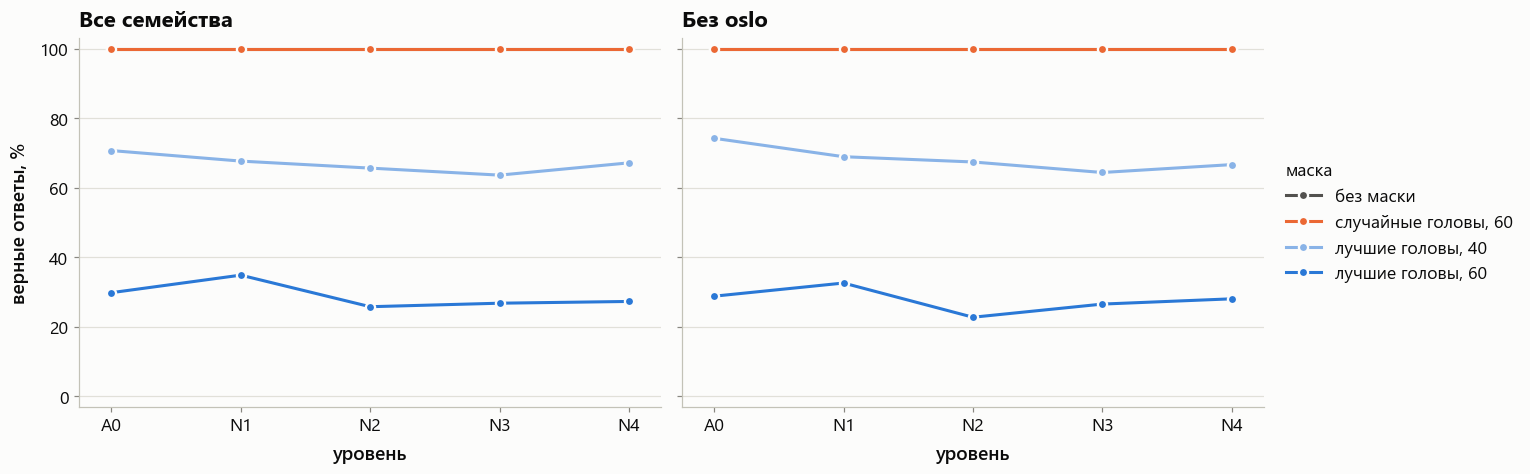

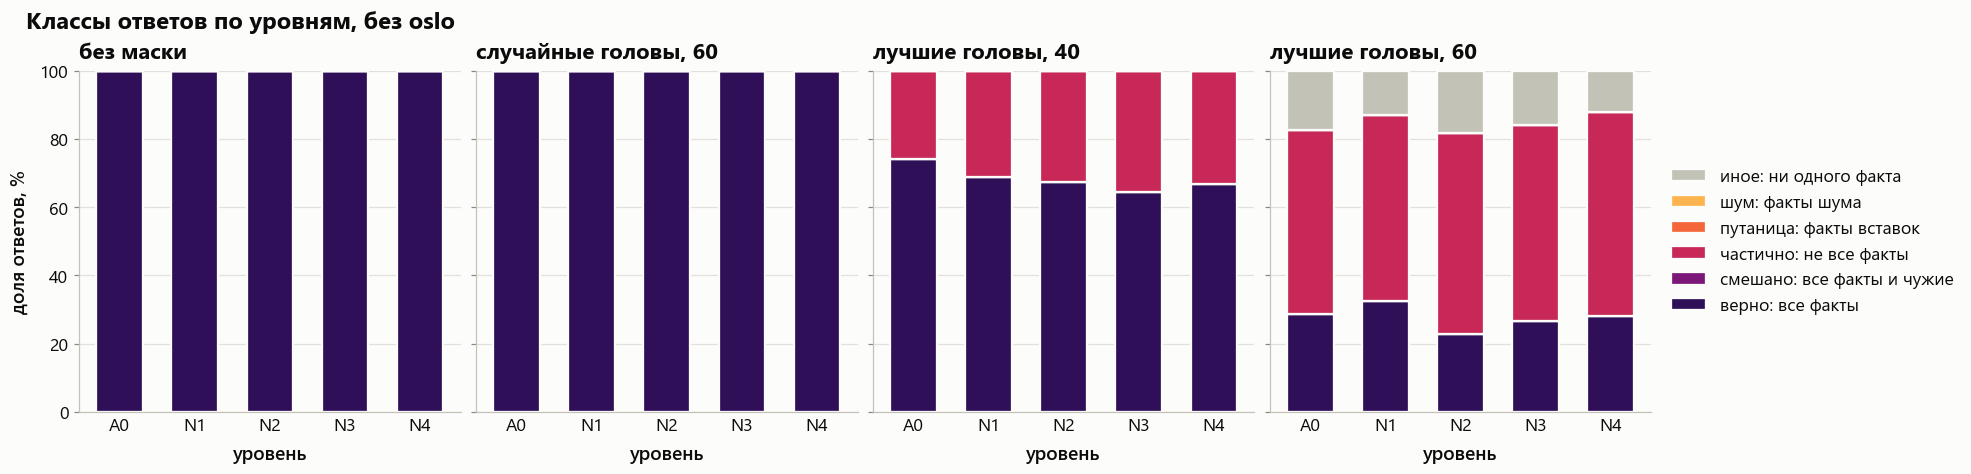

In [14]:
rest = sweep[~sweep["family"].isin(EXCLUDE)]
rest_none = rest[rest["run"] == "none"]
print(f"семейства: {sorted(rest['family'].unique())}; примеров без маски: {len(rest_none)}")

print("без маски: верные ответы, %")
display(hard.by_level(rest_none, by=("family", "level")))

print("верные ответы, %: без oslo")
display(hard.by_level(rest))
print("для сравнения — все три семейства")
display(hard.by_level(sweep))

axes = panels(2, 5.6, extra=2.6, sharey=True)
plots.level_lines(sweep, "correct", ax=axes[0], title="Все семейства")
plots.level_lines(rest, "correct", ax=axes[1], title="Без oslo")
axes[0].get_legend().remove()
axes[1].set_ylabel("")
show(axes, "N_rest_correct_by_level")

show(plots.class_panels(rest, hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по уровням, без oslo"), "N_rest_classes_by_run")

### На тех же примерах, без `oslo`

Доля примеров, верных без маски, которые остались верными под маской.

In [15]:
kept_rest = hard.paired(rest)
display(kept_rest)

print(f"разница с {BASE}, процентные пункты: без oslo")
display(kept_rest.loc[kept_rest.index != "n"].sub(kept_rest.loc[kept_rest.index != "n", BASE], axis=0).round(1))
print("та же разница по всем трём семействам")
display(kept.loc[kept.index != "n"].sub(base_kept, axis=0).round(1))

level,A0,N1,N2,N3,N4
n,132.0,132.0,132.0,132.0,132.0
random60,100.0,100.0,100.0,100.0,100.0
top40,74.2,68.9,67.4,64.4,66.7
top60,28.8,32.6,22.7,26.5,28.0


разница с A0, процентные пункты: без oslo


level,A0,N1,N2,N3,N4
random60,0.0,0.0,0.0,0.0,0.0
top40,0.0,-5.3,-6.8,-9.8,-7.5
top60,0.0,3.8,-6.1,-2.3,-0.8


та же разница по всем трём семействам


level,A0,N1,N2,N3,N4
random60,0.0,0.0,0.0,0.0,0.0
top40,0.0,-3.0,-5.0,-7.1,-3.5
top60,0.0,5.0,-4.0,-3.0,-2.5


### Где ломается: длина и глубина, без `oslo`

В ячейке два примера (по одному на семейство).

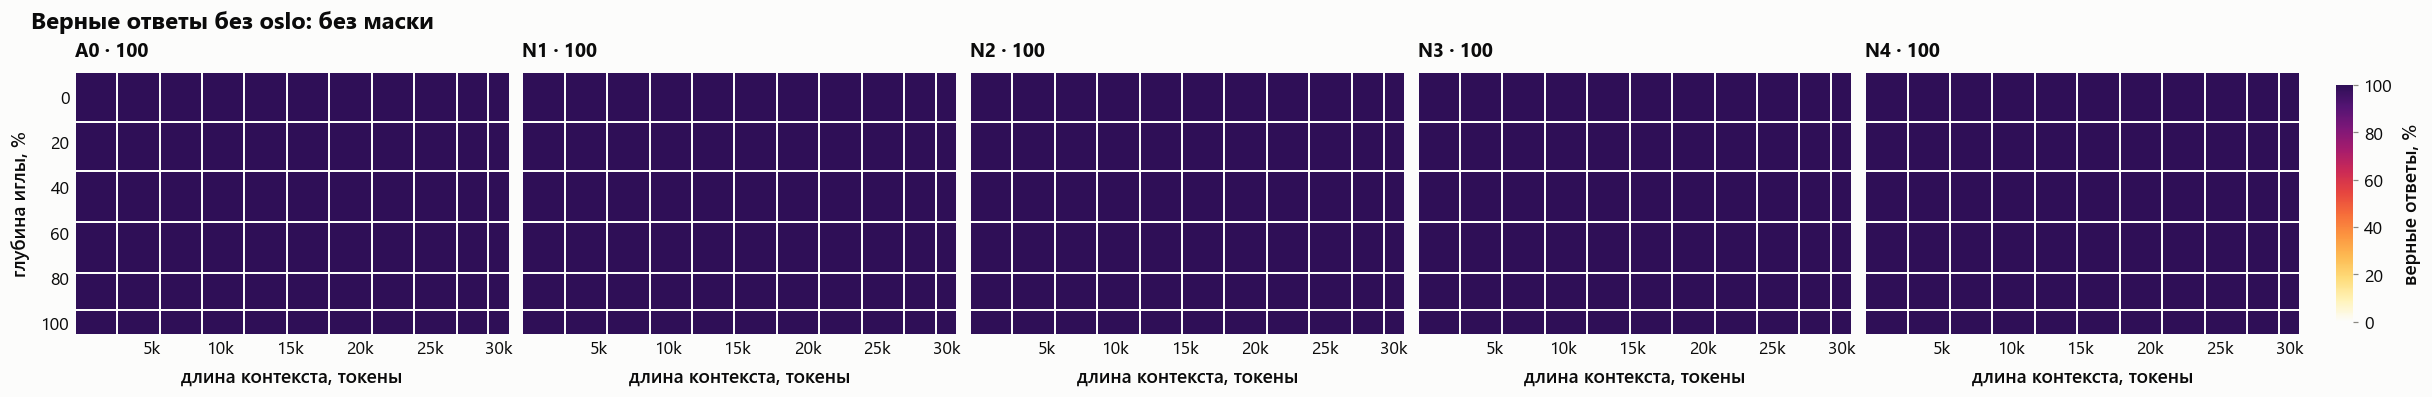

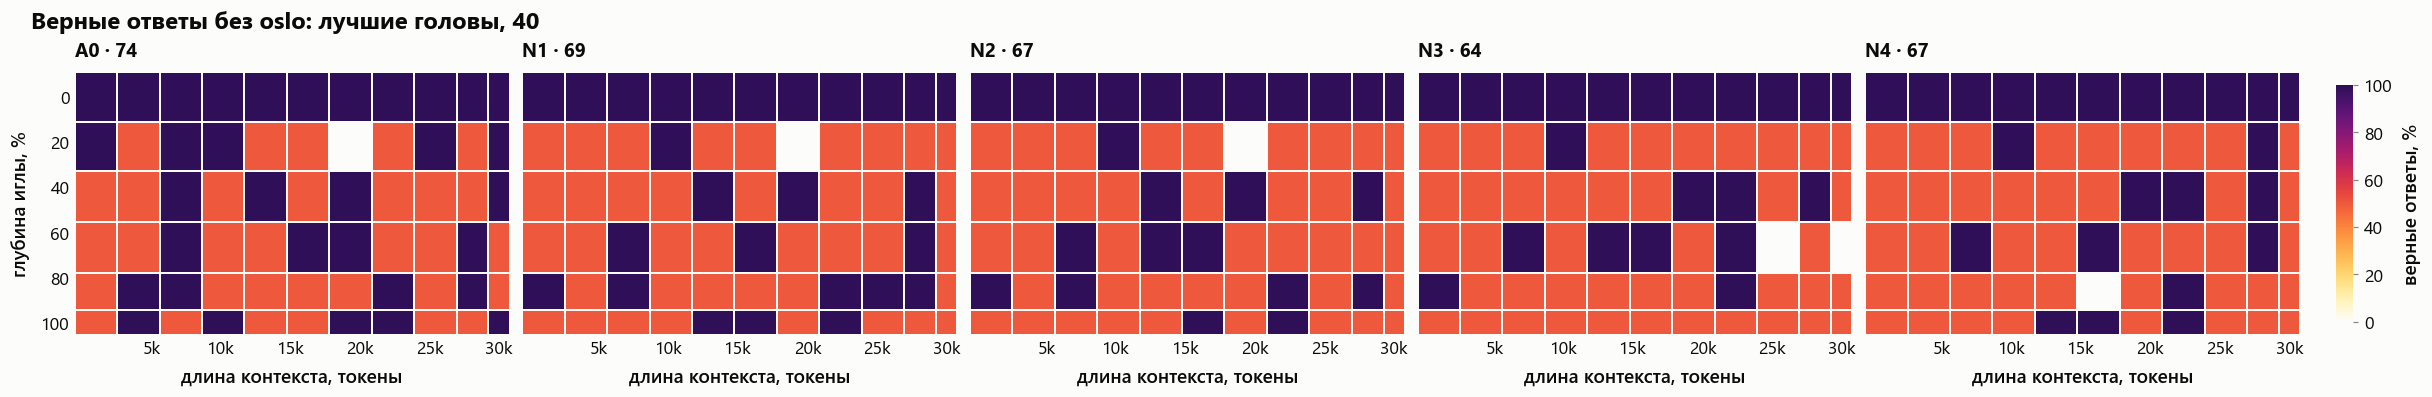

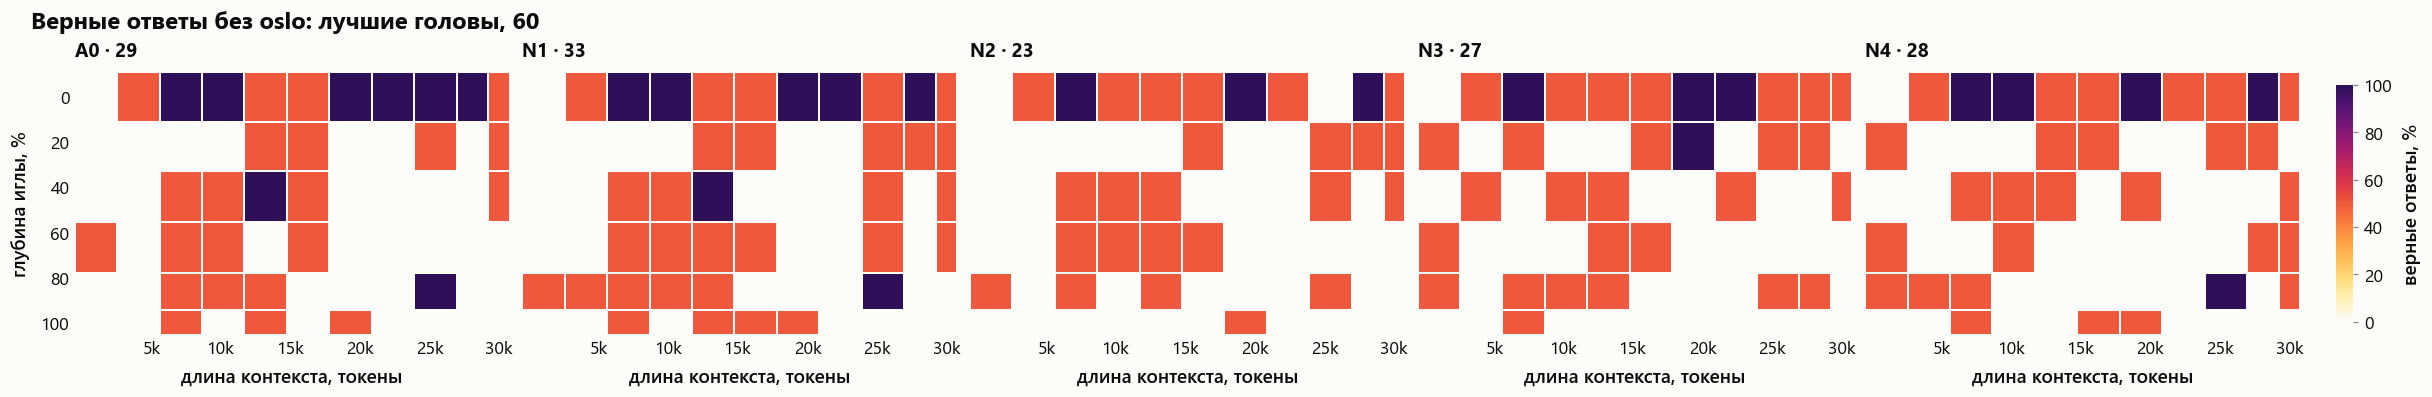

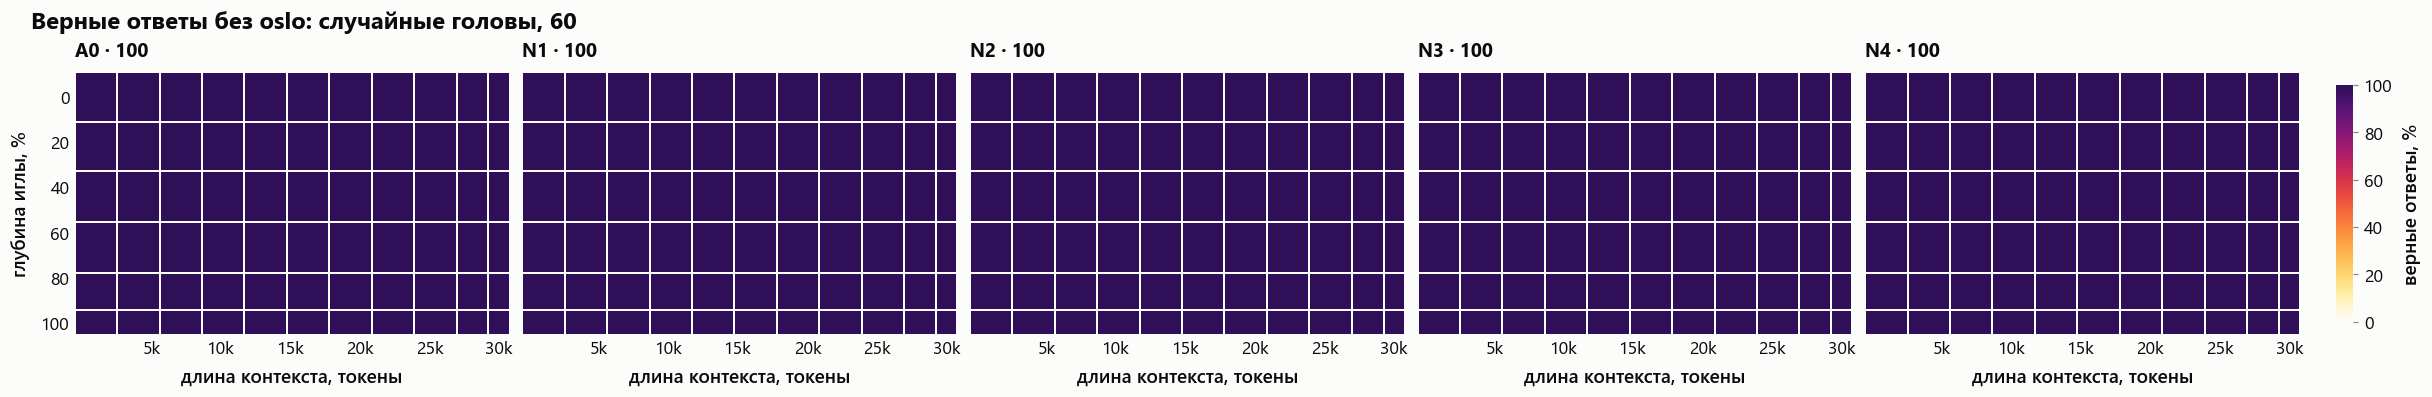

In [16]:
for run in [r for r in ("none", "top40", "top60", "random60") if r in set(rest["run"])]:
    part = rest[rest["run"] == run]
    name = plots.run_styles(rest)[run][1]
    show(plots.niah_grid(part.assign(run=part["level"]), {level: level for level in levels}, value="correct", columns=len(levels),
                         title=f"Верные ответы без oslo: {name}"), f"N_rest_niah_{run}")

## 2.4. Формулировки ответов: перефраз, замены, формы слов

Класс по фактам говорит, названы ли ключевые факты. Здесь тот же ответ разбирается подробнее: эталон разбит на части, и для каждой части смотрим, как она записана. Это тот же разбор, что в ноутбуках по задаче статьи и по оси A, с теми же списками формулировок: игла и эталон те же.

| Уровень формулировки | Что это | Пример |
|---|---|---|
| дословно | формулировка эталона | `cooked with` |
| другая форма слова | те же слова в другой форме, с другим артиклем или в другом порядке | `cooking it with`; `a brass bell`; `black clay bowl` |
| синоним, смысл сохранён | другие слова с тем же смыслом | `prepared using`; `when they arrive` вместо `at the entrance` |
| потеряна деталь | часть названа, но без существенной детали | `ring a bell` без `brass`; `smoked lemon` без `peel`; `red roof` без `slate` |
| нет | части в ответе нет | — |

Часть считается сохранённой на первых трёх уровнях. Списки формулировок лежат в `vizual/paraphrase.py` (`FACTS`); они собраны вручную по ответам прогонов оси A, и отнесение формулировки к уровню — моё решение.

| Структура ответа | Условие |
|---|---|
| точная фраза | эталон стоит в ответе дословно и подряд |
| все части дословно, другой порядок или вставка | все части дословно, но фраза не совпадает |
| все части, есть форма слова или синоним | все части сохранены, хотя бы одна не дословно — перефразированный полный ответ |
| не все части, остальные дословно | часть пропала, оставшиеся дословно — обрезанный ответ |
| не все части, есть форма, синоним или потеря детали | часть пропала или потеряла деталь |
| ни одной части | ответ не из иглы — в том числе ответ про шум |

Этот разбор смотрит только на части **иглы**. Попал ли в ответ шум, он не различает — это делает класс по фактам (раздел 2.2).

In [17]:
worded = paraphrase.annotate(sweep)
worded_none = worded[worded["run"] == "none"]
fact_names = {family: list(paraphrase.FACTS[worded.loc[worded["family"] == family, "reference"].iloc[0]]) for family in families}

# что именно написано вместо формулировки эталона: по всем прогонам
pd.set_option("display.max_rows", 200)
paraphrase.wordings(worded, top=5).set_index(["эталон", "факт", "уровень"])

написано  \
эталон                                                                       факт                  уровень                                                      
ring the brass bell at the entrance and sign the guest book with a green pen ring the brass bell   другая форма слова                       ring a brass bell   
                                                                                                   другая форма слова                  ringing the brass bell   
                                                                                                   другая форма слова                    ringing a brass bell   
                                                                                                   потеряна деталь                                ring a bell   
                                                                                                   потеряна деталь                              ring the bell   
                                                                             sign the guest book   другая форма слова                       sign a guest book   
                                                                                                   другая форма слова                        sign a guestbook   
                                                                                                   другая форма слова                  signing the guest book   
                                                                                                   синоним, смысл сохранён    sign their name in a guest book   
                                                                                                   синоним, смысл сохранён     sign their name in a guestbook   
                                                                                                   синоним, смысл сохранён  sign their name in the guest book   
                                                                                                   потеряна деталь                                 guest book   
                                                                                                   потеряна деталь                                  guestbook   
                                                                             with a green pen      синоним, смысл сохранён                     in a green pen   
                                                                                                   синоним, смысл сохранён                  using a green pen   
                                                                                                   потеряна деталь                                  green pen   
cooked with smoked lemon peel and served in a bowl of black clay             smoked lemon peel     потеряна деталь                               smoked lemon   
                                                                             served in             потеряна деталь                                    service   
                                                                             bowl of black clay    другая форма слова                 bowl made of black clay   
                                                                                                   другая форма слова                bowls made of black clay   
                                                                                                   потеряна деталь                                       bowl   
                                                                                                   потеряна деталь                                 black bowl   
a roof of red slate and a door painted with a white reindeer                 roof of red slate     другая форма слова                  roof made of red slate   
                                                                                                   другая форма слова       

### Без маски: как модель формулирует ответ на каждом уровне

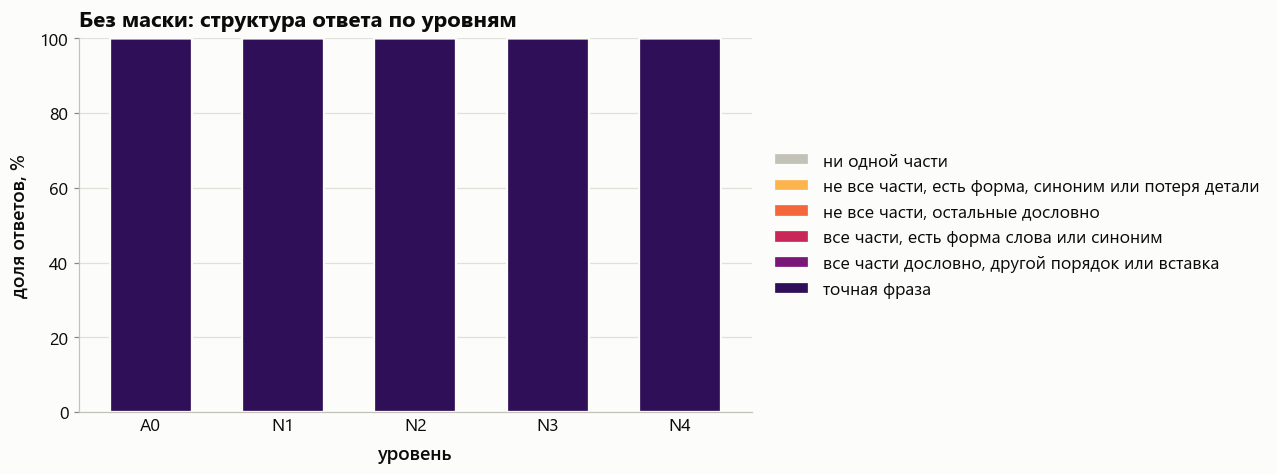

без маски: доля ответов каждой структуры, %


structure     точная фраза
family level              
cairo  A0            100.0
       N1            100.0
       N2            100.0
       N3            100.0
       N4            100.0
lisbon A0            100.0
       N1            100.0
       N2            100.0
       N3            100.0
       N4            100.0
oslo   A0            100.0
       N1            100.0
       N2            100.0
       N3            100.0
       N4            100.0

In [18]:
ax = plt.subplots(figsize=style.size(11.5, 4.2))[1]
show(plots.stacked(worded_none, "level", "structure", paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, xlabel="уровень", ax=ax,
                   title="Без маски: структура ответа по уровням"), "N_structure_none")

print("без маски: доля ответов каждой структуры, %")
display((pd.crosstab([worded_none["family"], worded_none["level"]], worded_none["structure"], normalize="index") * 100).reindex(
    columns=[k for k in paraphrase.STRUCTURES if k in set(worded_none["structure"])]).rename(columns=paraphrase.STRUCTURE_LABELS).round(1))

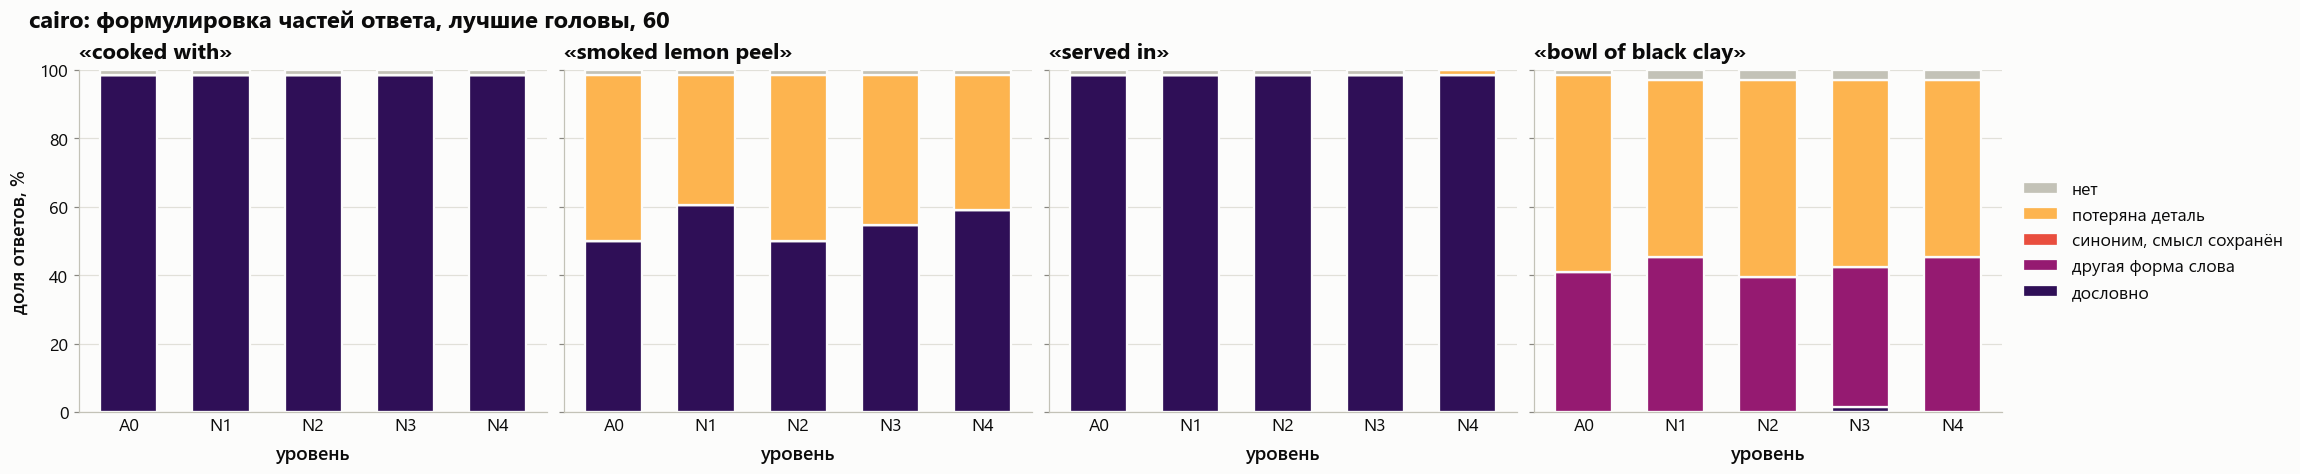

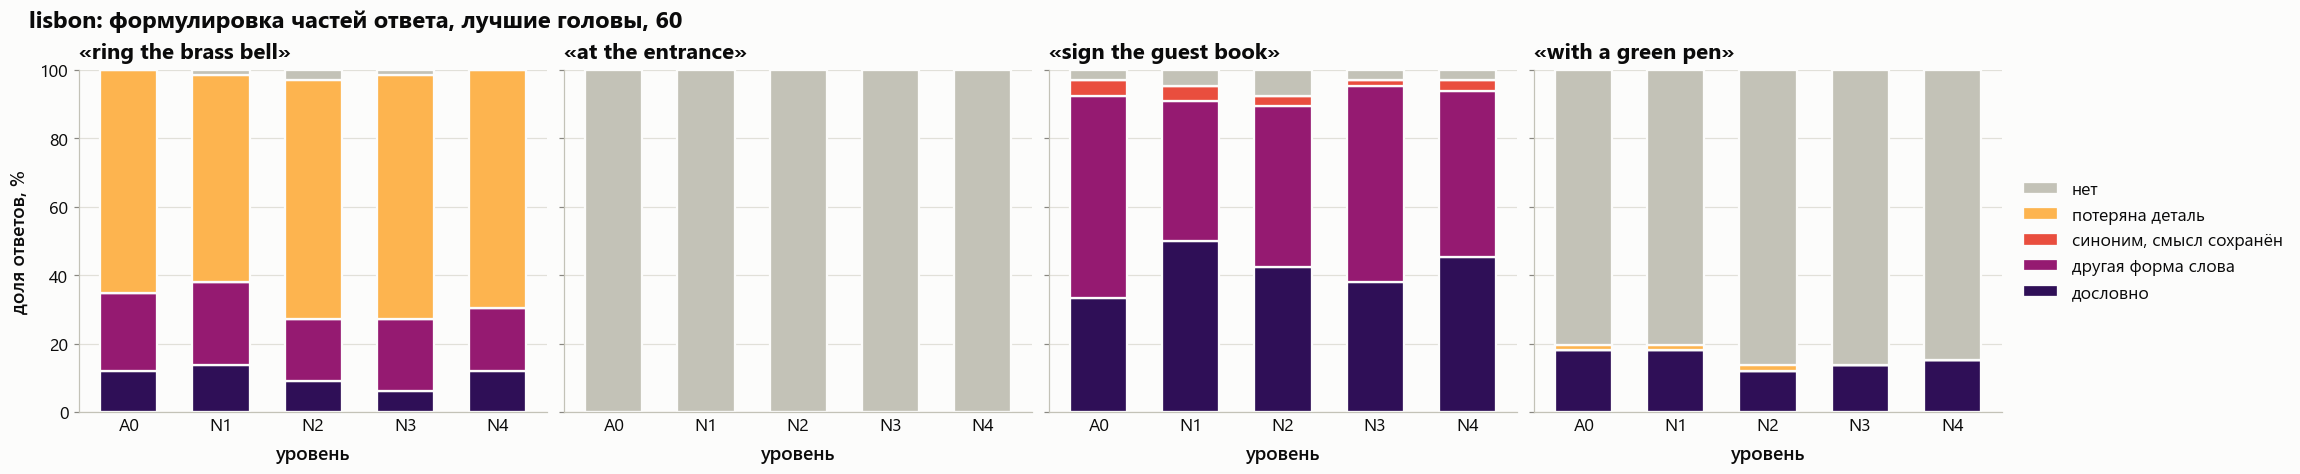

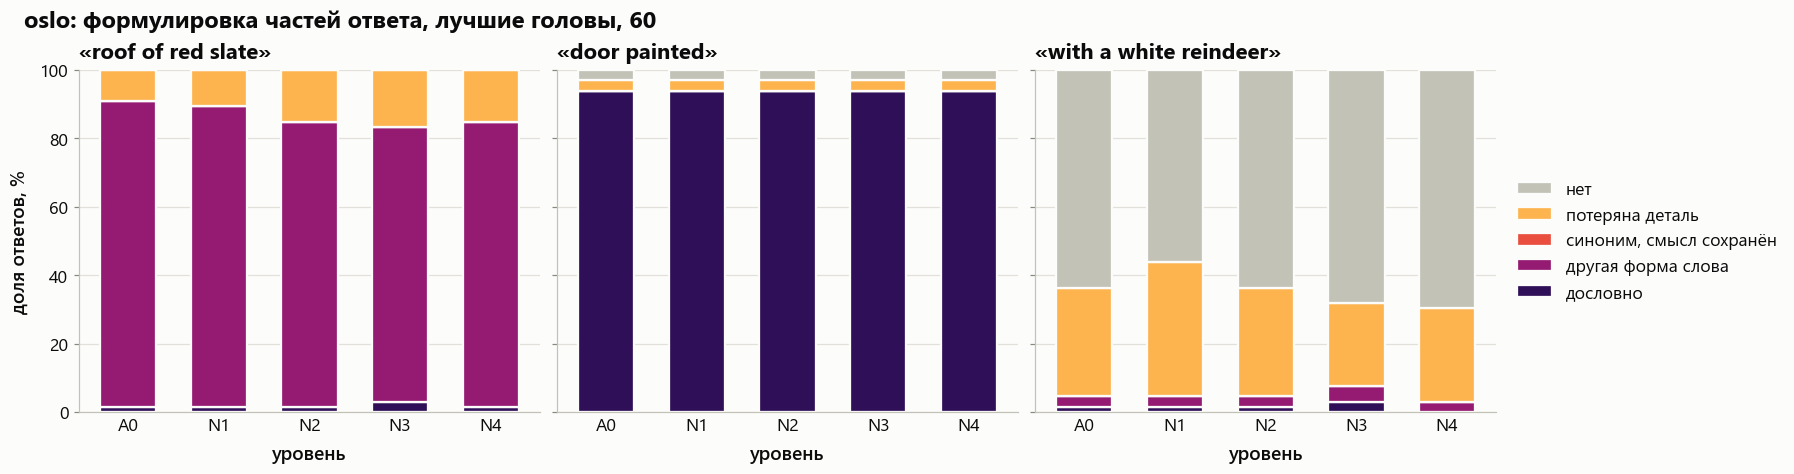

In [19]:
# как записана каждая часть эталона под маской 60 лучших голов: панель на часть, ряд на семейство
WORDING_RUN = "top60"
for family in families:
    part = worded[(worded["run"] == WORDING_RUN) & (worded["family"] == family)]
    names = fact_names[family]
    axes = panels(len(names), 4.6, extra=2.4, sharey=True)
    for ax, fact in zip(axes, names):
        plots.stacked(part, "level", fact, paraphrase.LEVELS, paraphrase.LEVEL_LABELS, xlabel="уровень", legend=ax is axes[-1], ax=ax, title=f"«{fact}»")
        if ax is not axes[0]:
            ax.set_ylabel("")
    axes[0].figure.suptitle(f"{family}: формулировка частей ответа, {plots.run_styles(sweep)[WORDING_RUN][1]}", x=0.01, ha="left", fontweight="bold")
    show(axes, f"N_fact_wordings_{family}")

### Как класс по фактам оценивает каждую структуру

По всем прогонам оси. `верно` — доля ответов класса «верно» по фактам; `частей` — сколько частей эталона сохранено (у `oslo` частей три, у остальных четыре).

In [20]:
by_structure = worded.groupby("structure").agg(ответов=("id", "size"), частей=("kept_facts", "mean"), верно=("correct", "mean"), слова_шума=("twin_words", "mean"),
                                               точная_фраза=("exact", "mean"), rouge1=("rouge1_recall", "mean")).reindex(paraphrase.STRUCTURES)
by_structure[["верно", "слова_шума", "точная_фраза"]] *= 100
display(by_structure.round(1).rename(index=paraphrase.STRUCTURE_LABELS))

print("структура против класса по фактам, число ответов")
display(pd.crosstab(worded["structure"], worded["answer_class"]).reindex(paraphrase.STRUCTURES).reindex(
    columns=[c for c in hard.CLASSES if c in set(worded["answer_class"])]).rename(index=paraphrase.STRUCTURE_LABELS, columns=hard.CLASS_LABELS))

,ответов,частей,верно,слова_шума,точная_фраза,rouge1
structure,,,,,,
точная фраза,1997.0,3.7,100.0,0.0,100.0,100.0
"все части дословно, другой порядок или вставка",NaN,NaN,NaN,NaN,NaN,NaN
"все части, есть форма слова или синоним",390.0,3.6,86.4,0.0,0.0,99.7
"не все части, остальные дословно",171.0,2.9,99.4,0.0,0.0,86.0
"не все части, есть форма, синоним или потеря детали",1394.0,2.1,30.5,0.0,0.0,77.8
ни одной части,8.0,0.0,0.0,0.0,0.0,32.6


структура против класса по фактам, число ответов


answer_class,верно: все факты,частично: не все факты,иное: ни одного факта
structure,,,
точная фраза,1997.0,0.0,0.0
"все части дословно, другой порядок или вставка",NaN,NaN,NaN
"все части, есть форма слова или синоним",337.0,53.0,0.0
"не все части, остальные дословно",170.0,1.0,0.0
"не все части, есть форма, синоним или потеря детали",425.0,822.0,147.0
ни одной части,0.0,0.0,8.0


### Под масками

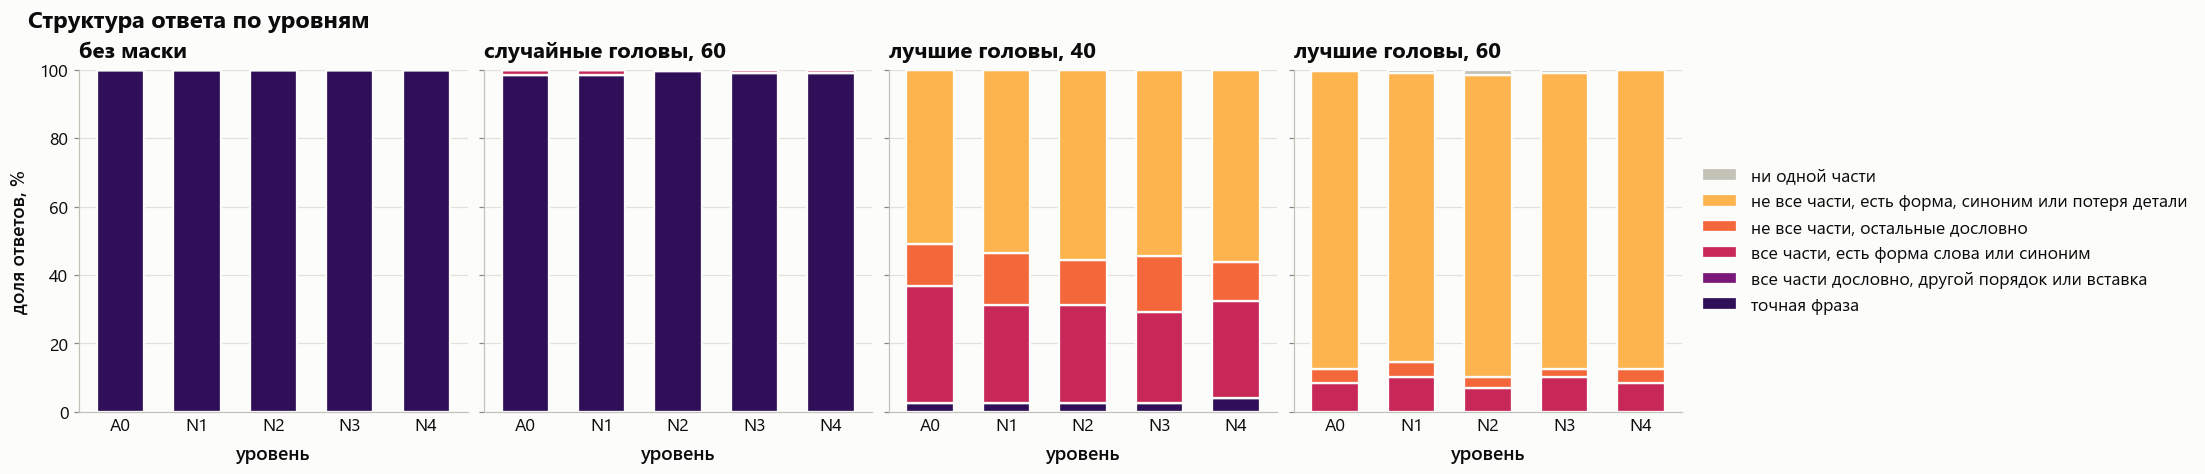

ответы со всеми частями эталона (дословно, формой слова или синонимом), %


level,A0,N1,N2,N3,N4
run,,,,,
none,100.0,100.0,100.0,100.0,100.0
random60,100.0,100.0,100.0,100.0,100.0
top40,36.9,31.3,31.3,29.3,32.3
top60,8.6,10.1,7.1,10.1,8.6


из них перефразированные (не точная фраза), %


level,A0,N1,N2,N3,N4
run,,,,,
none,0.0,0.0,0.0,0.0,0.0
random60,1.5,1.5,0.5,1.0,1.0
top40,93.2,91.9,91.9,91.4,87.5
top60,100.0,100.0,100.0,100.0,100.0


In [21]:
show(plots.class_panels(worded, paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, column="structure", title="Структура ответа по уровням"), "N_structure_by_run")

full = worded["structure"].isin(["exact", "reordered", "reworded"])
print("ответы со всеми частями эталона (дословно, формой слова или синонимом), %")
display(hard.by_level(worded.assign(full=full), "full"))
print("из них перефразированные (не точная фраза), %")
display(hard.by_level(worded[full].assign(reworded=lambda d: d["structure"] != "exact"), "reworded"))

In [22]:
# примеры: по два самых коротких ответа каждой структуры на уровнях с шумом
examples = worded[(~worded["exact"]) & (worded["level"] != BASE)].sort_values("n_tokens").groupby("structure").head(2)
examples.assign(структура=examples["structure"].map(paraphrase.STRUCTURE_LABELS)).set_index("структура").loc[
    [paraphrase.STRUCTURE_LABELS[k] for k in paraphrase.STRUCTURES if k in set(examples["structure"])],
    ["run", "family", "level", "answer_class", "response"]]

,run,family,level,answer_class,response
структура,,,,,
"все части, есть форма слова или синоним",top60,oslo,N3,correct,The oldest house in Oslo has a roof of red slate and a door painted with white reindeer.
"все части, есть форма слова или синоним",random60,oslo,N1,correct,The oldest house in Oslo has a red slate roof and a door painted with a white reindeer.
"не все части, остальные дословно",top60,oslo,N3,partial,The oldest house in Oslo has a roof of red slate and a door painted white.
"не все части, остальные дословно",top60,lisbon,N4,correct,Every visitor to the Lisbon Tram Museum is asked to ring the brass bell and sign the guest book.
"не все части, есть форма, синоним или потеря детали",top60,oslo,N1,other,The oldest house in Oslo has a red roof and a white door.
"не все части, есть форма, синоним или потеря детали",top60,oslo,N2,other,The oldest house in Oslo has a red roof and a white door.
ни одной части,top60,lisbon,N2,other,"Based on the content provided, the answer to the question ""What is the purpose of the book?"" is:\n\n**Answer:** To inform readers about the importance of understanding the App Store's approval process and the potenti..."
ни одной части,top60,lisbon,N1,other,"Based on the content provided, the answer to the question ""What is the purpose of the book?"" is:\n\n**Answer:** To inform readers about the process of starting a business, the challenges of managing growth, and the i..."


## 2.5. Формулировки ответов без семейства `oslo`

Тот же разбор, что в разделе 2.4, на семействах `cairo` и `lisbon`.

семейства: ['cairo', 'lisbon']; примеров без маски: 660


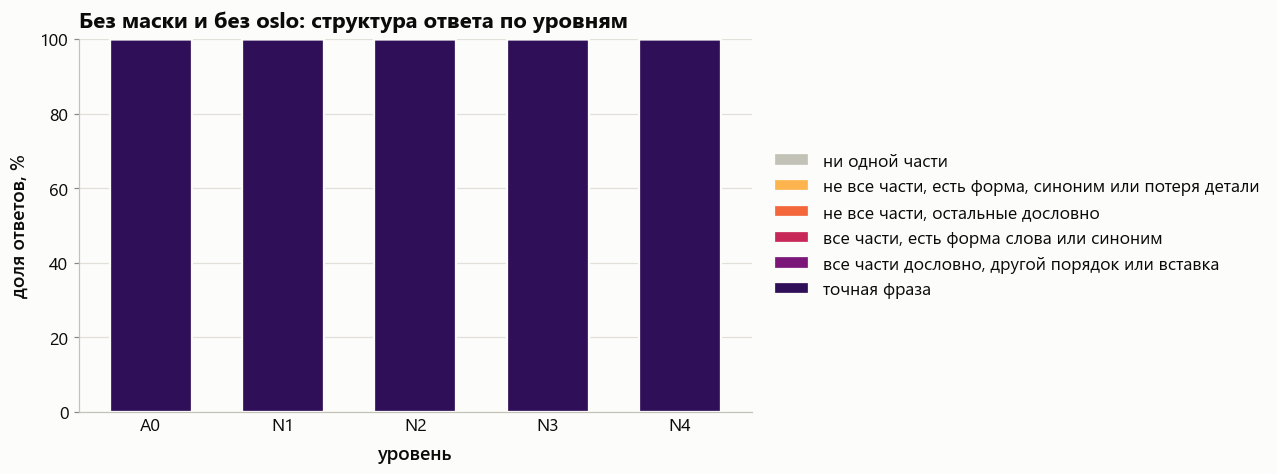

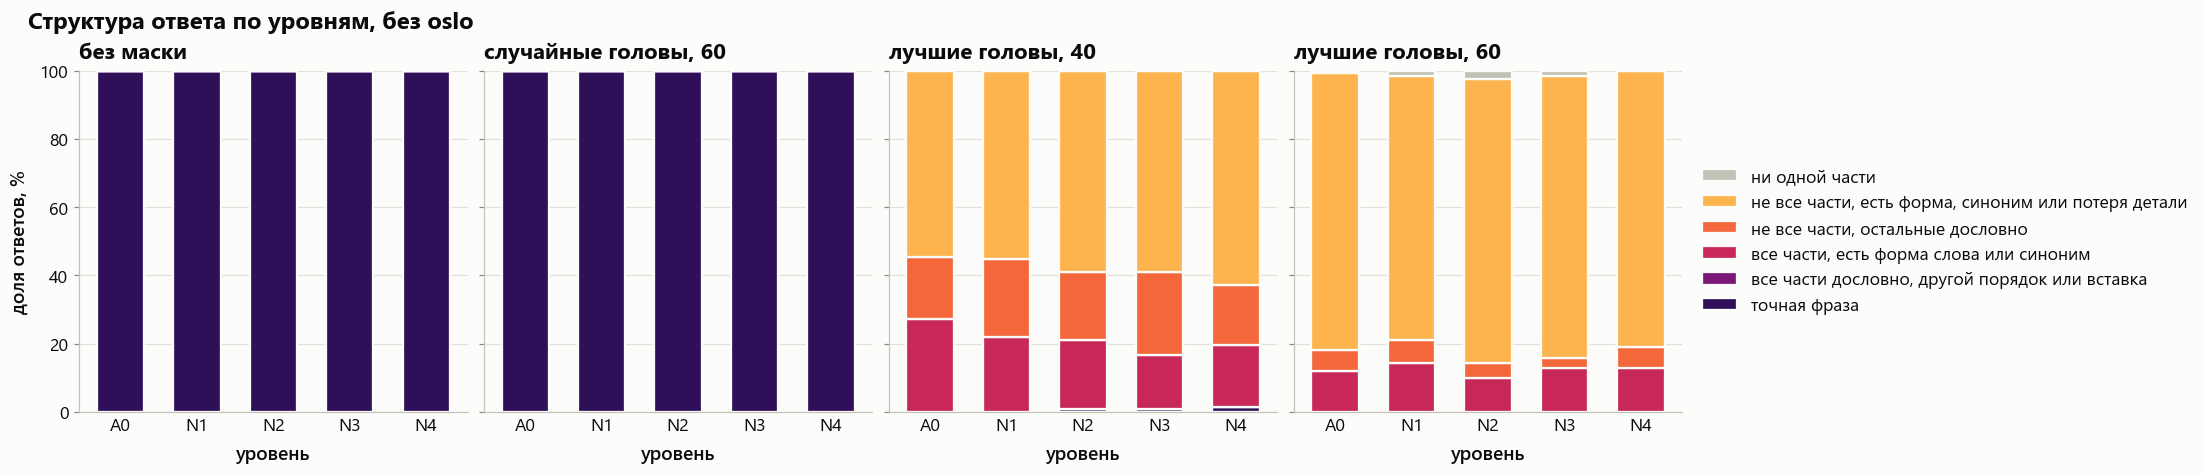

ответы со всеми частями эталона (дословно, формой слова или синонимом), %: без oslo


level,A0,N1,N2,N3,N4
run,,,,,
none,100.0,100.0,100.0,100.0,100.0
random60,100.0,100.0,100.0,100.0,100.0
top40,27.3,22.0,21.2,16.7,19.7
top60,12.1,14.4,9.8,12.9,12.9


то же по всем трём семействам


level,A0,N1,N2,N3,N4
run,,,,,
none,100.0,100.0,100.0,100.0,100.0
random60,100.0,100.0,100.0,100.0,100.0
top40,36.9,31.3,31.3,29.3,32.3
top60,8.6,10.1,7.1,10.1,8.6


структура против класса по фактам, число ответов: без oslo


answer_class,верно: все факты,частично: не все факты,иное: ни одного факта
structure,,,
точная фраза,1324.0,0.0,0.0
"все части дословно, другой порядок или вставка",NaN,NaN,NaN
"все части, есть форма слова или синоним",219.0,0.0,0.0
"не все части, остальные дословно",170.0,0.0,0.0
"не все части, есть форма, синоним или потеря детали",241.0,585.0,93.0
ни одной части,0.0,0.0,8.0


In [23]:
worded_rest = worded[~worded["family"].isin(EXCLUDE)]
worded_rest_none = worded_rest[worded_rest["run"] == "none"]
print(f"семейства: {sorted(worded_rest['family'].unique())}; примеров без маски: {len(worded_rest_none)}")

ax = plt.subplots(figsize=style.size(11.5, 4.2))[1]
show(plots.stacked(worded_rest_none, "level", "structure", paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, xlabel="уровень", ax=ax,
                   title="Без маски и без oslo: структура ответа по уровням"), "N_rest_structure_none")

show(plots.class_panels(worded_rest, paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, column="structure", title="Структура ответа по уровням, без oslo"), "N_rest_structure_by_run")

full_rest = worded_rest["structure"].isin(["exact", "reordered", "reworded"])
print("ответы со всеми частями эталона (дословно, формой слова или синонимом), %: без oslo")
display(hard.by_level(worded_rest.assign(full=full_rest), "full"))
print("то же по всем трём семействам")
display(hard.by_level(worded.assign(full=full), "full"))

print("структура против класса по фактам, число ответов: без oslo")
display(pd.crosstab(worded_rest["structure"], worded_rest["answer_class"]).reindex(paraphrase.STRUCTURES).reindex(
    columns=[c for c in hard.CLASSES if c in set(worded_rest["answer_class"])]).rename(index=paraphrase.STRUCTURE_LABELS, columns=hard.CLASS_LABELS))

# 3. Метрики голов

Только прогон без маски. Скоры считаются по верно отвеченным примерам.

| Метрика | Годится? | Почему |
|---|---|---|
| `copy_recall`, `copy_count` — скор копирования из статьи | да | игла и вопрос не менялись, ответ списывается из иглы; шум в этот скор не входит — засчитывается только токен внутри ответа иглы |
| частота активации | да | доля примеров, где голова скопировала хотя бы один токен иглы |
| `needle_mass`, `needle_attention_mass` — масса внимания на ответе в игле | да | куда голова смотрит, независимо от формулировки ответа |
| `needle_sentence_mass` — масса на всей игле | да, основная для сравнения с шумом | игла и вставка — целые предложения, поэтому сравнивать нужно предложение с предложением |
| `competing_max_mass` — масса на самой сильной вставке шума | да | одна вставка против одной иглы: сравнимо между уровнями с одной и с тремя вставками |
| `competing_mass` — масса на всём шуме вместе | да, с оговоркой | на N3 это сумма по трём вставкам, на остальных уровнях — по одной; между ними напрямую не сравнивается |
| `copy_sentence` и `copy_competing` — копирование из иглы и из шума | да | оба делятся на длину ответа иглы, поэтому сравнимы друг с другом и с `copy_count` |
| `supporting_mass` | нет | это внимание на вставки с частью ответа, на оси N таких нет: значения равны нулю |

На уровне A0 вставок нет, поэтому метрики шума там равны нулю по построению.

In [24]:
heads = data.Heads(NONE, samples=none, ok="correct")      # в скор входят верные ответы; примеры A0 берутся из прогона оси A
detect = data.Heads(DETECT)                               # детекция на простой задаче (условие — успех по ROUGE-1, как в статье)
reference = detect.score(METRIC)                          # скор детекции, [слой, голова]
order = np.argsort(-reference.ravel(), kind="stable")     # головы от лучшей к худшей по детекции
place = {int(i): rank + 1 for rank, i in enumerate(order)}
total_heads = reference.size

common = hard.common_cells(heads.samples)                 # места иглы, отвеченные верно на всех уровнях
print(f"примеров с метриками голов: {len(heads.samples)}; на местах, верных на всех уровнях: {common.sum()} ({common.sum() // len(levels)} на уровень)")

scores = hard.level_scores(heads, METRIC, where=common)                                              # {уровень: [слой, голова]}
rankings = {level: heads.ranking(METRIC, hard.level_mask(heads, level, common)) for level in levels}   # рейтинг голов самого уровня

примеров с метриками голов: 990; на местах, верных на всех уровнях: 990 (198 на уровень)


## 3.1. Те же графики, что на исходной задаче

Каждый график из ноутбука по задаче статьи, построенный отдельно для каждого уровня. Здесь рейтинг считается заново на самом уровне — чтобы увидеть, как выглядела бы детекция, проведённая на тексте с шумом.

### Распределение голов по скору (рис. 3 статьи)

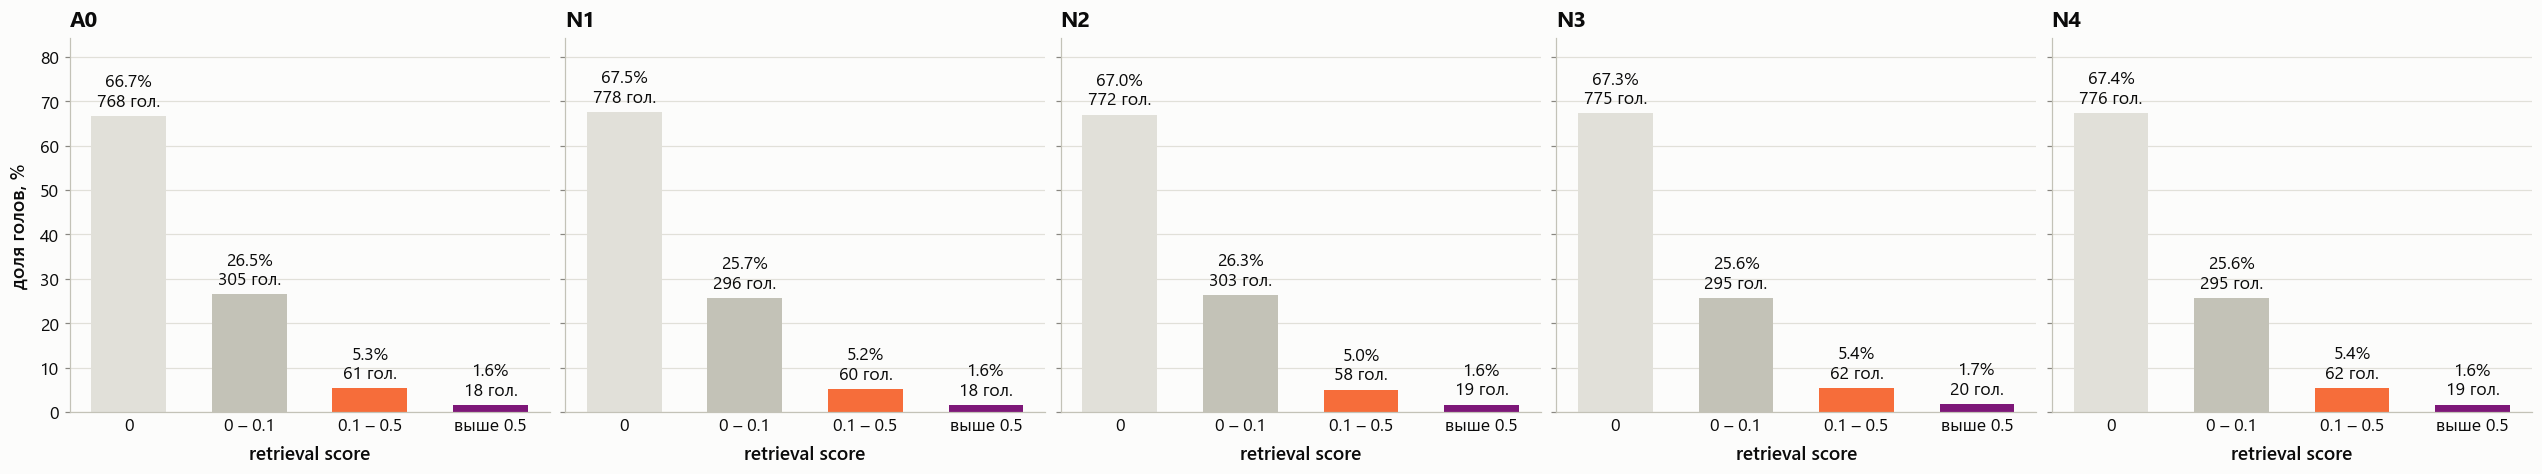

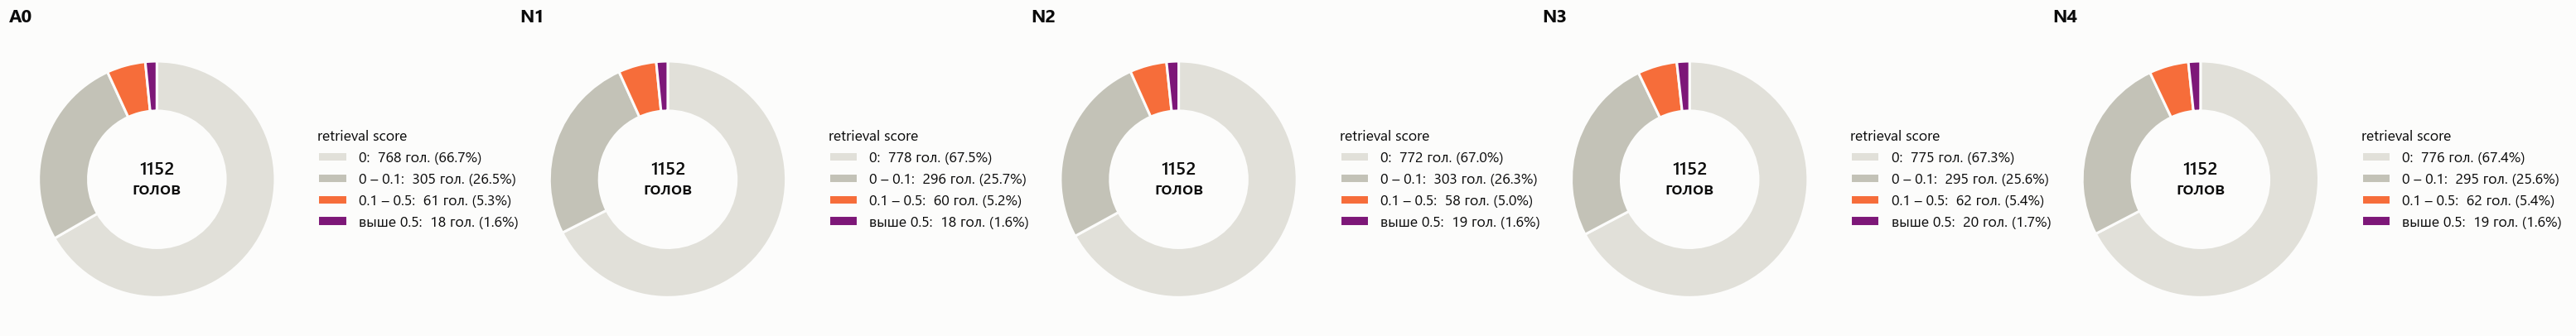

доля голов, %


,ровно 0,0 – 0.1,0.1 – 0.5,выше 0.5,голов выше 0.1
детекция,57.9,36.7,4.2,1.2,62.0
A0,66.7,26.5,5.3,1.6,79.0
N1,67.5,25.7,5.2,1.6,78.0
N2,67.0,26.3,5.0,1.6,77.0
N3,67.3,25.6,5.4,1.7,82.0
N4,67.4,25.6,5.4,1.6,81.0


In [25]:
axes = panels(len(levels), 4.6, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_distribution(scores[level], ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "N_score_distribution")

axes = panels(len(levels), 5.6, 3.6)
for ax, level in zip(axes, levels):
    plots.score_pie(scores[level], ax=ax, title=level)
show(axes, "N_score_pie")

share = lambda s: {"ровно 0": (s == 0).mean() * 100, "0 – 0.1": ((s > 0) & (s <= 0.1)).mean() * 100, "0.1 – 0.5": ((s > 0.1) & (s <= 0.5)).mean() * 100,
                   "выше 0.5": (s > 0.5).mean() * 100, f"голов выше {THRESHOLD}": float((s > THRESHOLD).sum())}
print("доля голов, %")
display(pd.DataFrame({"детекция": share(reference), **{level: share(scores[level]) for level in levels}}).T.round(1))

### Скор и частота активации (рис. 4 статьи)

Головы упорядочены по скору самого уровня. Частота активации — доля примеров уровня, в которых голова скопировала хотя бы один токен иглы.

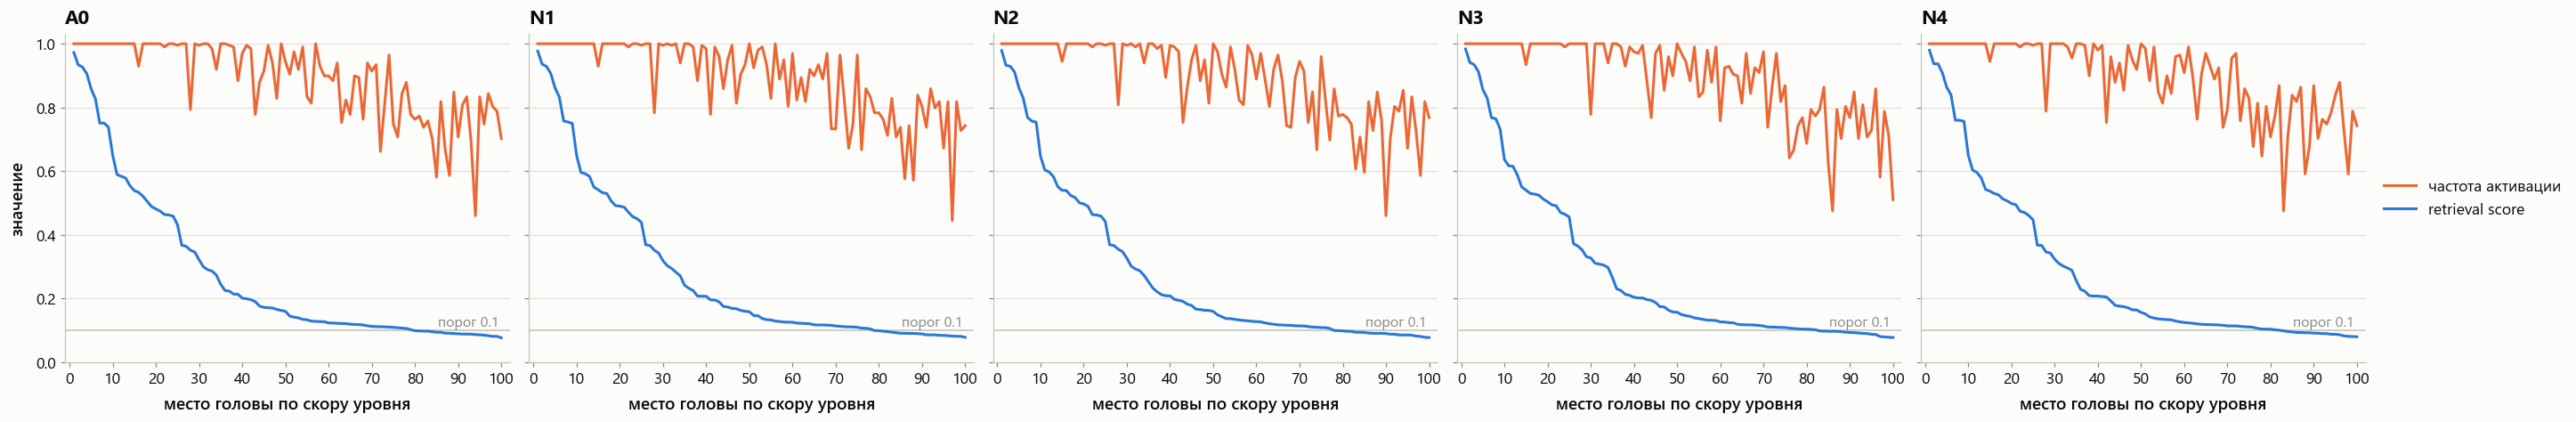

голов, активных во всех примерах уровня: {'A0': 31, 'N1': 31, 'N2': 30, 'N3': 33, 'N4': 32}


In [26]:
axes = panels(len(levels), 4.8, extra=2.2, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_vs_frequency(rankings[level], top=100, threshold=THRESHOLD, ax=ax, title=level)
    ax.set_xlabel("место головы по скору уровня")
    if ax is not axes[-1]:
        ax.get_legend().remove()
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "N_score_vs_frequency")

print("голов, активных во всех примерах уровня:", {level: int((rankings[level]["frequency"] == 1).sum()) for level in levels})

### Скор каждой головы (рис. 5 статьи)

Одна шкала цвета на всех панелях.

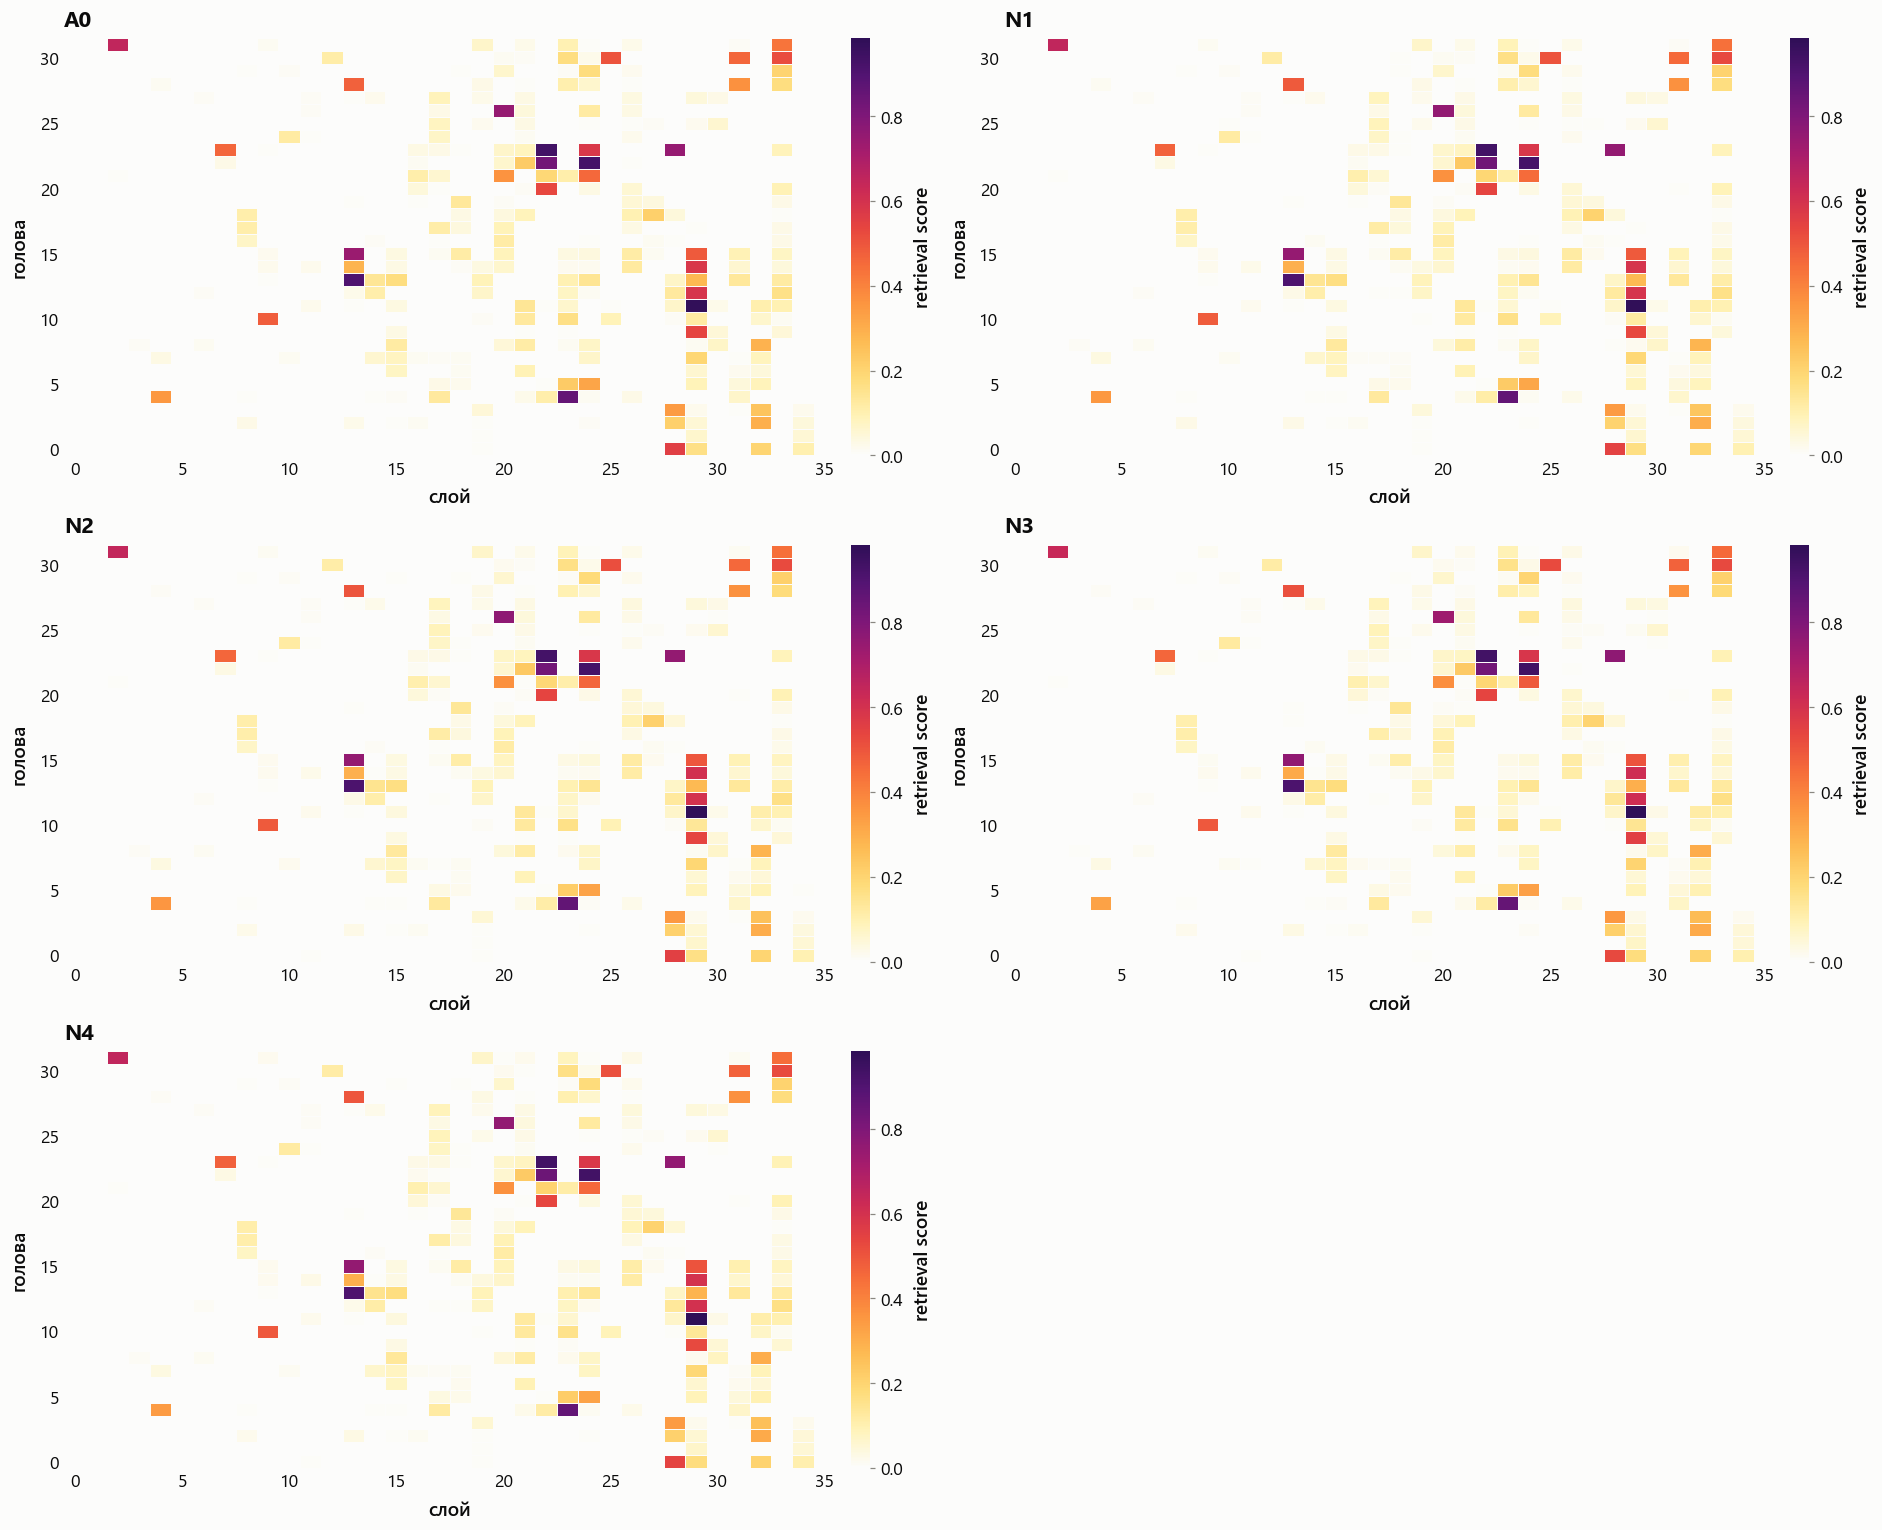

In [27]:
vmax = max(float(s.max()) for s in scores.values())
rows = -(-len(levels) // 2)
fig, axes = plt.subplots(rows, 2, figsize=style.size(17, 4.6 * rows))
for ax, level in zip(axes.ravel(), levels):
    plots.head_heatmap(scores[level], heads.layers, vmax=vmax, ax=ax, title=level)
for ax in axes.ravel()[len(levels):]:
    ax.set_visible(False)
show(axes, "N_head_heatmap")

### 20 лучших голов уровня

Рейтинг самого уровня. Сравнение с рейтингом детекции — в разделе 3.2.

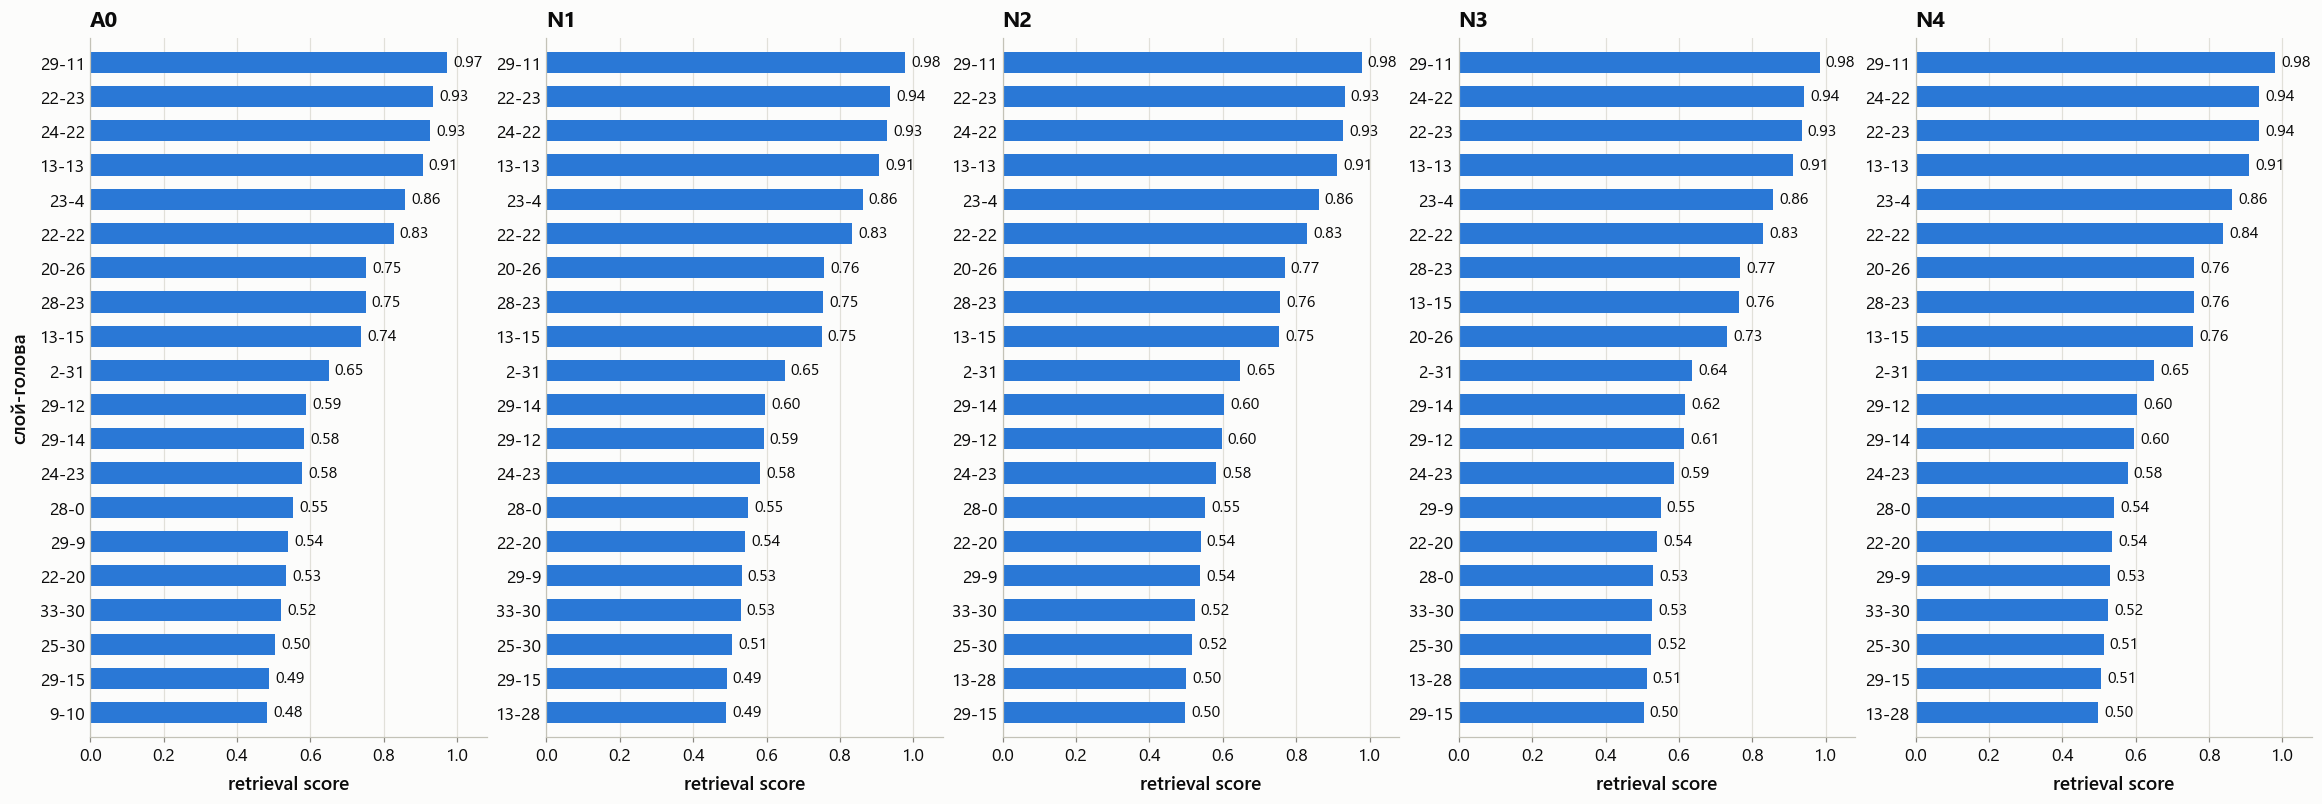

In [28]:
axes = panels(len(levels), 4.2, 7.2)
for ax, level in zip(axes, levels):
    plots.top_heads(rankings[level], k=20, threshold=THRESHOLD, ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "N_top_heads")

## 3.2. Сохраняется ли рейтинг детекции

Порядок голов на каждом уровне против порядка детекции на простой задаче: корреляция Спирмена по всем головам и число общих голов среди 20, 40 и 60 лучших. Строка A0 — это перенос на другие иглы без усложнения; остальные уровни сравниваются с ней.

In [29]:
display(hard.ranking_table(scores, reference))

print(f"то же против {BASE} (та же игла и вопрос, добавлен только шум)")
display(hard.ranking_table({level: scores[level] for level in twin_levels}, scores[BASE]))

,спирмен,top20,top40,top60
условие,,,,
A0,0.844,18/20,36/40,47/60
N1,0.853,18/20,36/40,47/60
N2,0.855,18/20,36/40,48/60
N3,0.849,18/20,36/40,47/60
N4,0.856,18/20,36/40,47/60


то же против A0 (та же игла и вопрос, добавлен только шум)


,спирмен,top20,top40,top60
условие,,,,
N1,0.968,19/20,40/40,58/60
N2,0.967,19/20,40/40,58/60
N3,0.957,19/20,39/40,57/60
N4,0.964,19/20,39/40,57/60


### Корреляция скоров: исходные головы и наша задача

Точка — голова: по горизонтали её скор в детекции на простой задаче, по вертикали — на уровне. На диагонали скор сохранён. Выделены головы, которые детекция относит к retrieval-головам (скор выше порога).

r — корреляция Пирсона (совпадают ли сами значения), ρ — Спирмена (совпадает ли порядок). По всем головам корреляцию во многом задают сотни голов со скором около нуля, поэтому отдельно посчитано по исходным retrieval-головам.

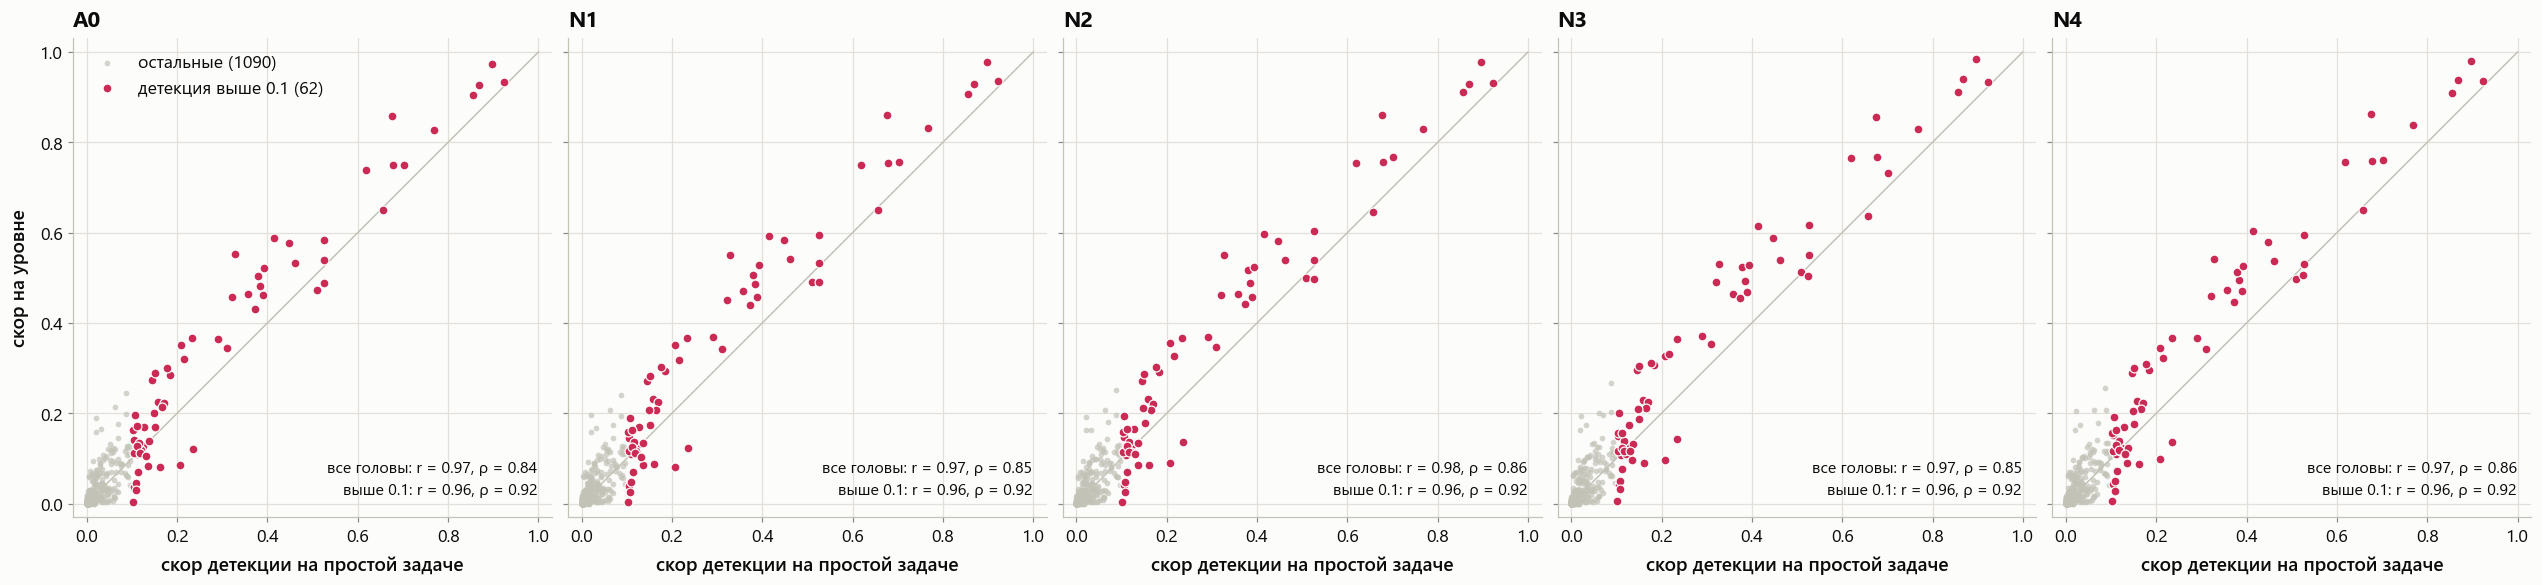

условие               A0                   N1                   N2         \
                   голов пирсон спирмен голов пирсон спирмен голов пирсон   
головы                                                                      
20 лучших детекции    20  0.942   0.910    20  0.941   0.920    20  0.943   
40 лучших детекции    40  0.951   0.946    40  0.952   0.948    40  0.953   
60 лучших детекции    60  0.962   0.919    60  0.963   0.920    60  0.963   
все головы          1152  0.974   0.844  1152  0.975   0.853  1152  0.975   
детекция выше 0.1     62  0.962   0.915    62  0.963   0.916    62  0.963   

условие                       N3                   N4                 
                   спирмен голов пирсон спирмен голов пирсон спирмен  
головы                                                                
20 лучших детекции   0.919    20  0.938   0.914    20  0.942   0.910  
40 лучших детекции   0.947    40  0.953   0.953    40  0.954   0.946  
60 лучших детекции   0.927    60  0.963   0.928    60  0.964   0.924  
все головы           0.855  1152  0.974   0.849  1152  0.975   0.856  
детекция выше 0.1    0.922    62  0.962   0.923    62  0.963   0.919

In [30]:
axes = panels(len(levels), 4.6, 4.9, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_scatter(reference, scores[level], threshold=THRESHOLD, ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
        ax.get_legend().remove()
show(axes, "N_score_scatter")

display(hard.correlation_table(scores, reference, order, threshold=THRESHOLD).unstack("условие").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False))

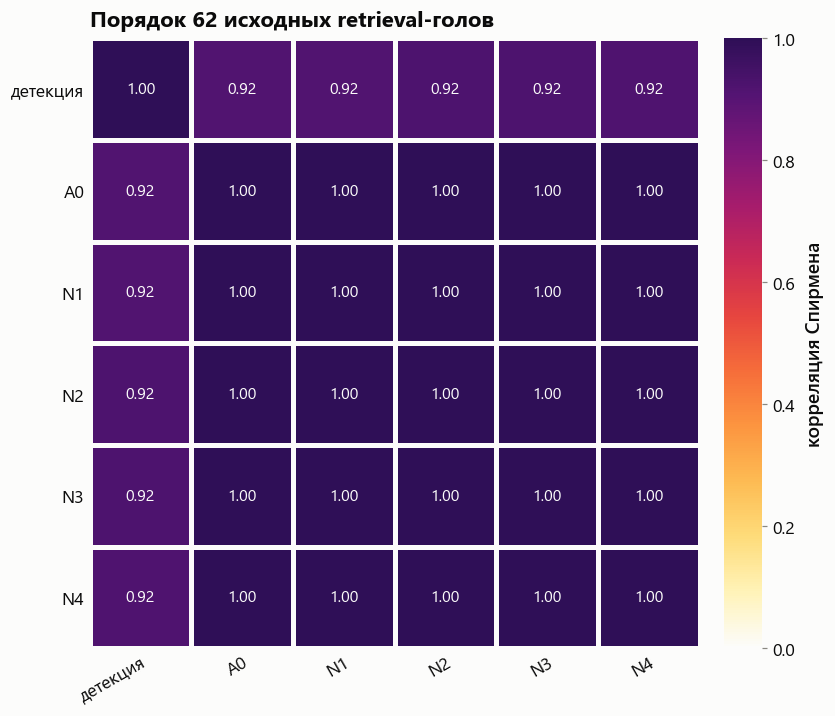

In [31]:
# между всеми условиями сразу: корреляция Спирмена по головам детекции выше порога
found = reference.ravel() > THRESHOLD
show(plots.correlation({"детекция": reference.ravel()[found], **{level: scores[level].ravel()[found] for level in levels}},
                       title=f"Порядок {int(found.sum())} исходных retrieval-голов"), "N_score_correlation")

## 3.3. Значения голов детекции по уровням

Головы стоят в порядке детекции и не переупорядочиваются. Если роль сохраняется, линии уровней идут вместе.

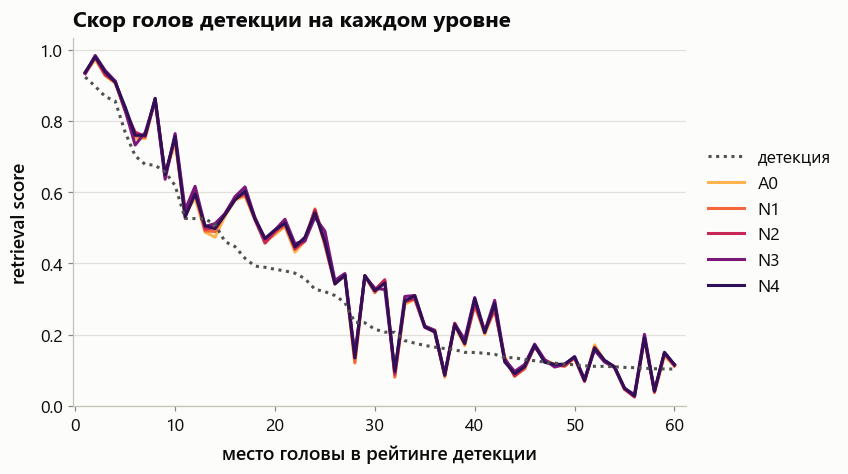

средний скор голов, которые отключаются масками


,детекция,A0,N1,N2,N3,N4
20 лучших,0.6109,0.6780,0.6825,0.6848,0.6886,0.6862
40 лучших,0.4248,0.4928,0.4954,0.4980,0.5022,0.4991
60 лучших,0.3229,0.3703,0.3718,0.3739,0.3777,0.3751


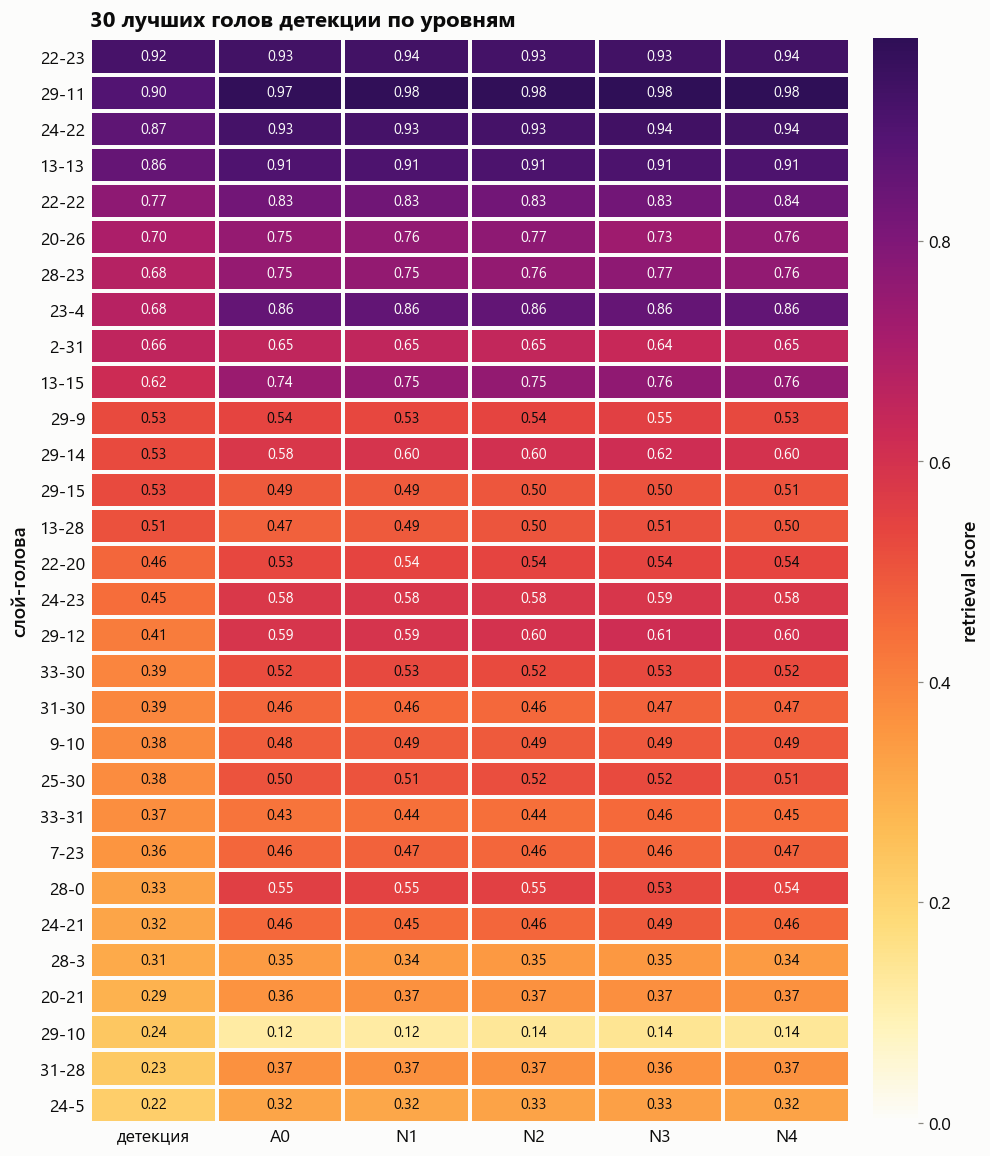

In [32]:
show(plots.rank_profile(scores, order, top=60, reference=reference, title="Скор голов детекции на каждом уровне"), "N_rank_profile")

print("средний скор голов, которые отключаются масками")
display(hard.top_means({"детекция": reference, **scores}, order))

top = 30
table = pd.DataFrame({"детекция": reference.ravel()[order[:top]], **{level: scores[level].ravel()[order[:top]] for level in levels}},
                     index=[heads.name(i) for i in order[:top]])
show(plots.head_table(table, title=f"{top} лучших голов детекции по уровням"), "N_head_table")

## 3.4. Контроль: дословные ответы

Скор копирования зависит от того, насколько дословно модель отвечает. Тот же расчёт повторён только на ответах с точной фразой: там число скопированных токенов одинаково на всех уровнях.

ответов с точной фразой: {'A0': 198, 'N1': 198, 'N2': 198, 'N3': 198, 'N4': 198}


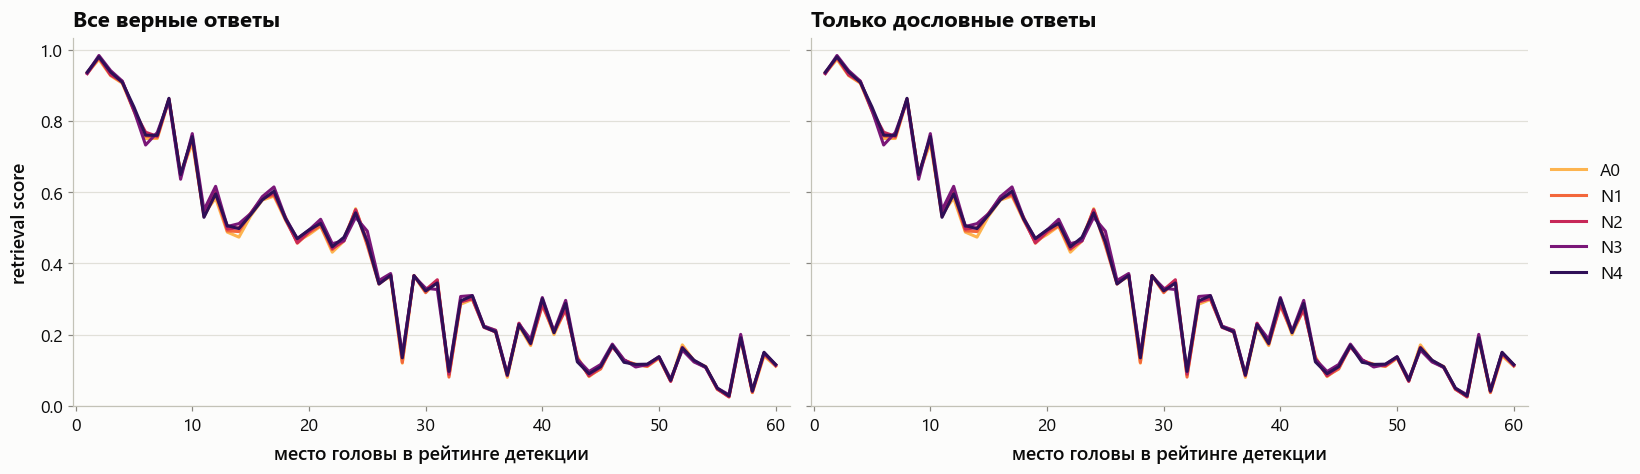

средний скор лучших голов детекции: все верные ответы


,A0,N1,N2,N3,N4
20 лучших,0.6780,0.6825,0.6848,0.6886,0.6862
40 лучших,0.4928,0.4954,0.4980,0.5022,0.4991
60 лучших,0.3703,0.3718,0.3739,0.3777,0.3751


только дословные ответы


,A0,N1,N2,N3,N4
20 лучших,0.6780,0.6825,0.6848,0.6886,0.6862
40 лучших,0.4928,0.4954,0.4980,0.5022,0.4991
60 лучших,0.3703,0.3718,0.3739,0.3777,0.3751


In [33]:
exact = heads.samples["exact"].to_numpy()
print("ответов с точной фразой:", {level: int((exact & heads.samples["correct"] & (heads.samples["level"] == level)).sum()) for level in levels})
exact_scores = hard.level_scores(heads, METRIC, where=exact)

axes = panels(2, 6.6, extra=1.6, sharey=True)
plots.rank_profile(scores, order, top=60, legend=False, ax=axes[0], title="Все верные ответы")
plots.rank_profile(exact_scores, order, top=60, ax=axes[1], title="Только дословные ответы")
axes[1].set_ylabel("")
show(axes, "N_exact_control")

print("средний скор лучших голов детекции: все верные ответы")
display(hard.top_means(scores, order))
print("только дословные ответы")
display(hard.top_means(exact_scores, order))

## 3.5. Куда головы смотрят: масса внимания на игле

Головы стоят в порядке детекции (по копированию).

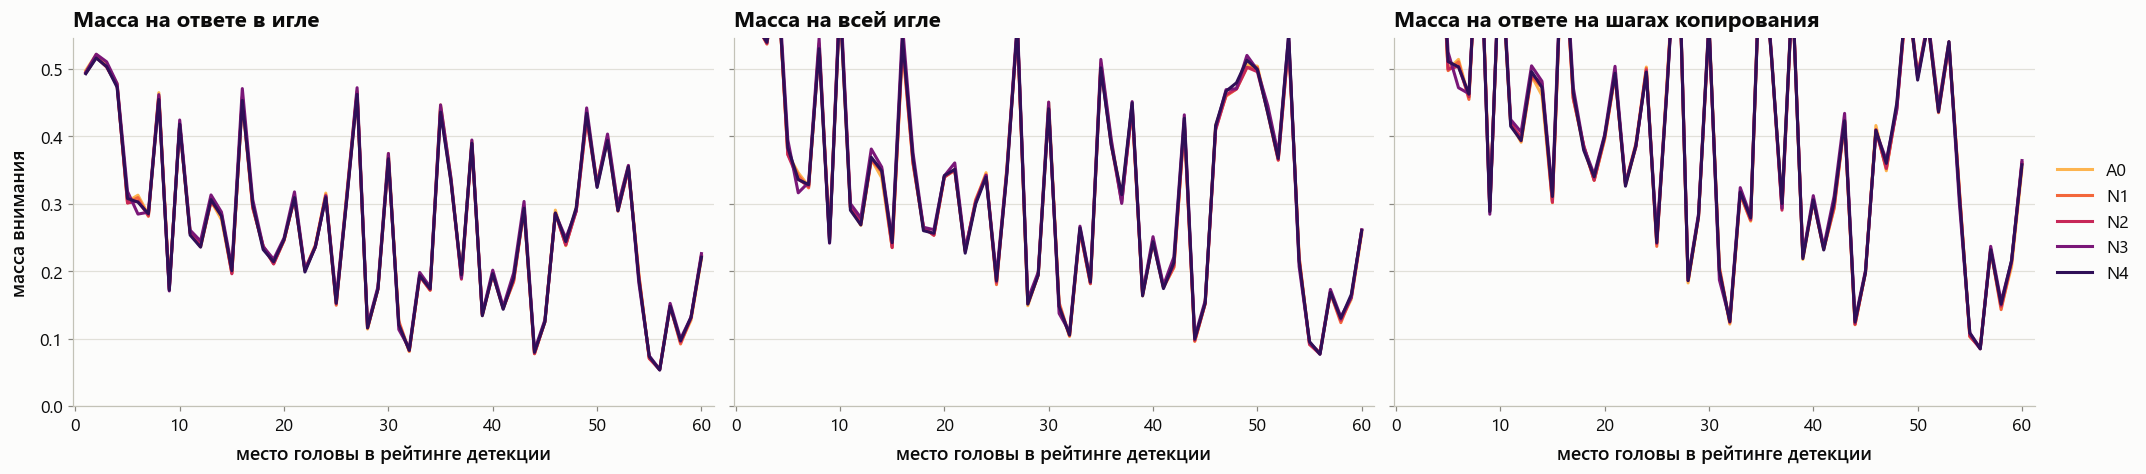

Масса на ответе в игле (needle_mass): среднее у лучших голов детекции


,A0,N1,N2,N3,N4
20 лучших,0.3341,0.3327,0.3328,0.3373,0.3325
40 лучших,0.2904,0.2889,0.2886,0.2927,0.2883
60 лучших,0.2666,0.2650,0.2648,0.2690,0.2650


Масса на всей игле (needle_sentence_mass): среднее у лучших голов детекции


,A0,N1,N2,N3,N4
20 лучших,0.4050,0.4044,0.4056,0.4128,0.4056
40 лучших,0.3496,0.3487,0.3490,0.3549,0.3493
60 лучших,0.3308,0.3298,0.3300,0.3356,0.3313


Масса на ответе на шагах копирования (needle_attention_mass): среднее у лучших голов детекции


,A0,N1,N2,N3,N4
20 лучших,0.5437,0.5436,0.5450,0.5500,0.5454
40 лучших,0.4667,0.4661,0.4666,0.4709,0.4669
60 лучших,0.4211,0.4202,0.4208,0.4249,0.4214


In [34]:
mass_metrics = {"needle_mass": "Масса на ответе в игле", "needle_sentence_mass": "Масса на всей игле", "needle_attention_mass": "Масса на ответе на шагах копирования"}
masses = {metric: hard.level_scores(heads, metric, where=common) for metric in mass_metrics}

axes = panels(3, 6.0, extra=1.4, sharey=True)
for ax, (metric, name) in zip(axes, mass_metrics.items()):
    plots.rank_profile(masses[metric], order, top=60, ylabel="масса внимания", legend=ax is axes[-1], ax=ax, title=name)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "N_mass_profile")

for metric, name in mass_metrics.items():
    print(f"{name} ({metric}): среднее у лучших голов детекции")
    display(hard.top_means(masses[metric], order))

## 3.6. Игла против шума

Главный раздел оси: смотрят ли retrieval-головы на шум и копируют ли из него. Все значения — на тех же верно отвеченных примерах, то есть модель в итоге ответила правильно.

### Масса внимания: игла и самая сильная вставка шума

`needle_sentence_mass` — доля внимания головы на предложении иглы; `competing_max_mass` — на той вставке шума, которая на данном шаге получает больше всего. Это сравнение «одно предложение против одного предложения», оно одинаково осмысленно при одной вставке и при трёх.

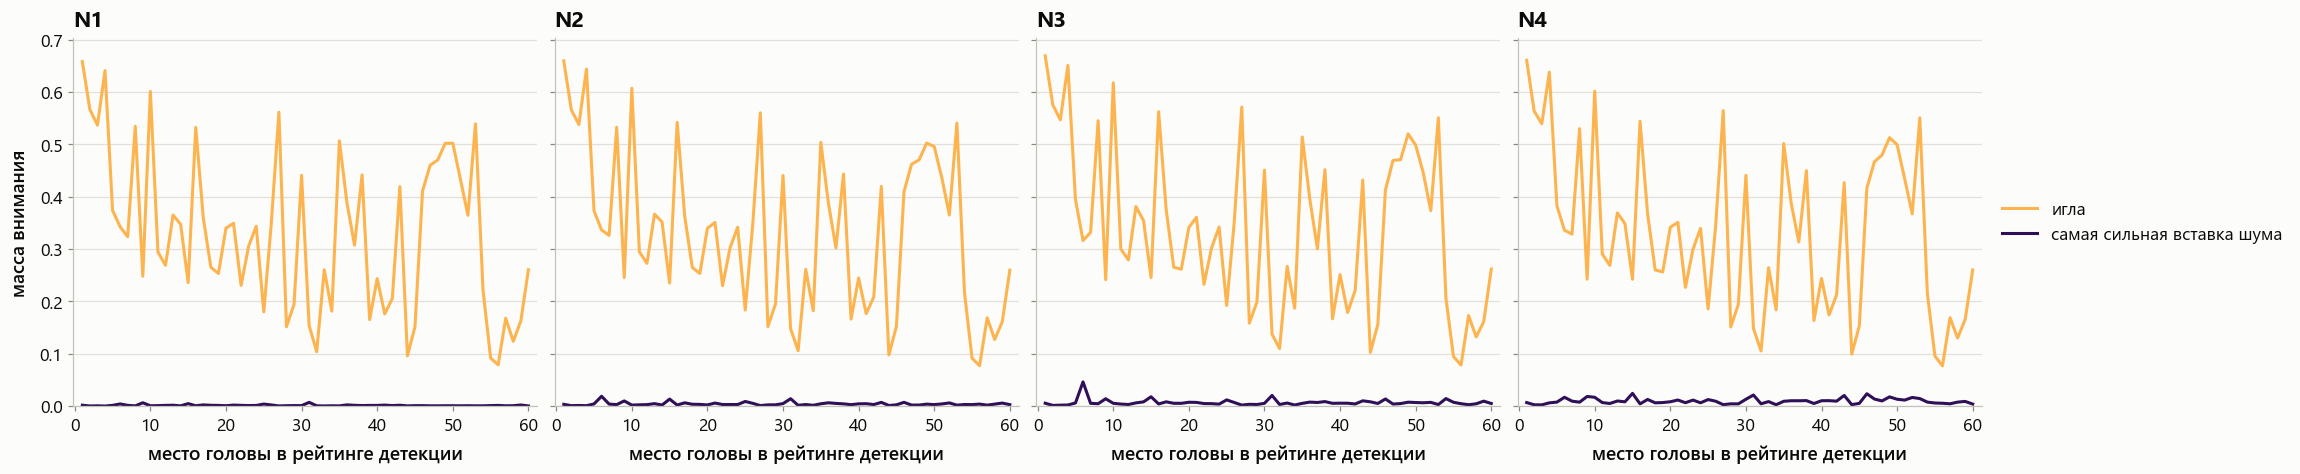

масса на всей игле: среднее у лучших голов детекции


,A0,N1,N2,N3,N4
20 лучших,0.4050,0.4044,0.4056,0.4128,0.4056
40 лучших,0.3496,0.3487,0.3490,0.3549,0.3493
60 лучших,0.3308,0.3298,0.3300,0.3356,0.3313


масса на самой сильной вставке шума


,N1,N2,N3,N4
20 лучших,0.0017,0.0045,0.0081,0.0094
40 лучших,0.0016,0.0044,0.0071,0.0090
60 лучших,0.0014,0.0042,0.0070,0.0096


масса на всём шуме вместе (на N3 вставок три)


,N1,N2,N3,N4
20 лучших,0.0017,0.0045,0.0122,0.0094
40 лучших,0.0016,0.0044,0.0107,0.0090
60 лучших,0.0014,0.0042,0.0104,0.0096


In [35]:
needle = masses["needle_sentence_mass"]
rival = hard.level_scores(heads, "competing_max_mass", where=common)
rivals_all = hard.level_scores(heads, "competing_mass", where=common)

top_mass = max(float(needle[level].ravel()[order[:60]].max()) for level in levels)
axes = panels(len(twin_levels), 4.8, extra=1.6, sharey=True)
for ax, level in zip(axes, twin_levels):
    plots.rank_profile({"игла": needle[level], "самая сильная вставка шума": rival[level]}, order, top=60, ylabel="масса внимания",
                       legend=ax is axes[-1], ax=ax, title=level)
    ax.set_ylim(0, top_mass * 1.05)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "N_needle_vs_twin")

print("масса на всей игле: среднее у лучших голов детекции")
display(hard.top_means(needle, order))
print("масса на самой сильной вставке шума")
display(hard.top_means({level: rival[level] for level in twin_levels}, order))
print("масса на всём шуме вместе (на N3 вставок три)")
display(hard.top_means({level: rivals_all[level] for level in twin_levels}, order))

### Избирательность

Какая доля внимания, отданного игле или самой сильной вставке шума, приходится на иглу: `игла / (игла + шум)`. 1 — голова смотрит только на иглу, 0.5 — поровну, 0 — только на шум.

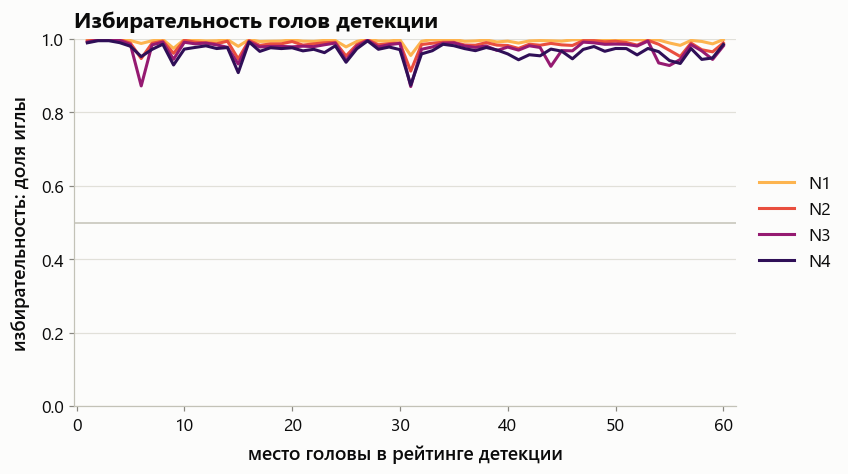

средняя избирательность лучших голов детекции


,N1,N2,N3,N4
20 лучших,0.9947,0.9861,0.9767,0.9734
40 лучших,0.9938,0.9842,0.9756,0.9700
60 лучших,0.9942,0.9840,0.9736,0.9672


для сравнения — остальные головы, которые смотрят на иглу или шум (сумма массы выше 0.05): число и средняя избирательность


,N1,N2,N3,N4
голов,234.000,241.000,246.000,252.000
избирательность,0.985,0.957,0.934,0.911


In [36]:
select = {level: hard.selectivity(needle[level], rival[level]) for level in twin_levels}
ax = plots.rank_profile(select, order, top=60, ylabel="избирательность: доля иглы", title="Избирательность голов детекции")
ax.set_ylim(0, 1.0)
ax.axhline(0.5, color=style.THEME.axis, linewidth=1, zorder=1)
show(ax, "N_selectivity")

print("средняя избирательность лучших голов детекции")
display(hard.top_means(select, order))

rest_heads = order[60:]
looking = {level: (needle[level].ravel()[rest_heads] + rival[level].ravel()[rest_heads]) > 0.05 for level in twin_levels}
print("для сравнения — остальные головы, которые смотрят на иглу или шум (сумма массы выше 0.05): число и средняя избирательность")
display(pd.DataFrame({level: {"голов": int(looking[level].sum()), "избирательность": float(select[level].ravel()[rest_heads][looking[level]].mean())} for level in twin_levels}).round(3))

### Игла и шум по головам

Точка — голова: по горизонтали масса на игле, по вертикали — на самой сильной вставке шума. Выделены 60 лучших голов детекции. Чем ниже точка под диагональю, тем избирательнее голова.

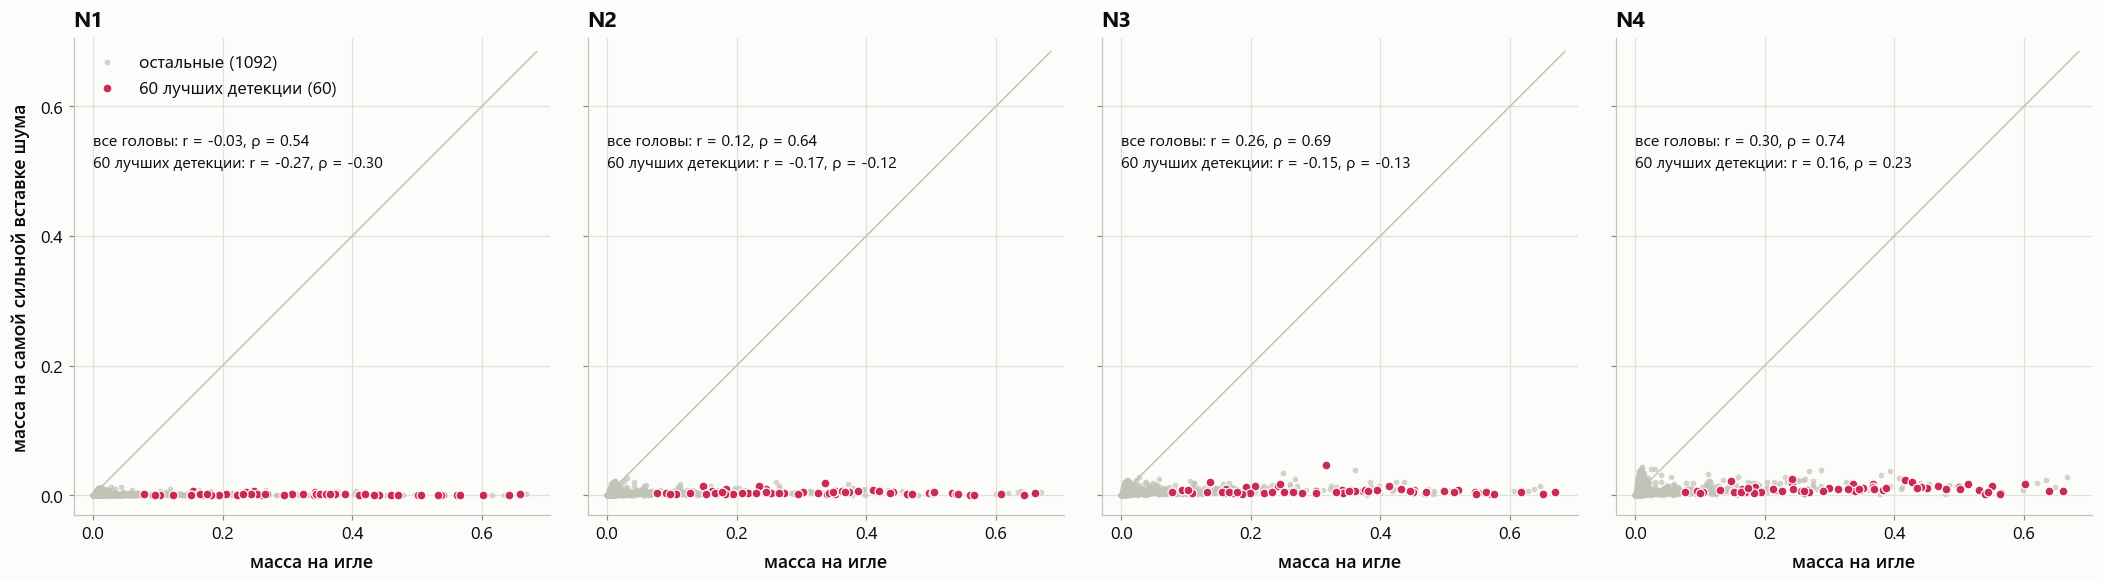

In [37]:
best = np.zeros(total_heads, dtype=bool)
best[order[:60]] = True
limit = max(float(needle[level].max()) for level in twin_levels) * 1.02
axes = panels(len(twin_levels), 4.8, 5.0, sharey=True)
for ax, level in zip(axes, twin_levels):
    plots.score_scatter(needle[level], rival[level], mark=best, mark_label="60 лучших детекции", top=limit, xlabel="масса на игле",
                        ylabel="масса на самой сильной вставке шума", ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
        ax.get_legend().remove()
show(axes, "N_needle_twin_scatter")

In [38]:
# головы, которые больше всего смотрят на шум, на уровне с тремя вставками рядом
LOOK = "N3"
most = np.argsort(-rival[LOOK].ravel(), kind="stable")[:20]
pd.DataFrame({"голова": [heads.name(i) for i in most], "место в детекции": [place[int(i)] for i in most],
              "скор копирования на уровне": scores[LOOK].ravel()[most], "масса на игле": needle[LOOK].ravel()[most],
              "масса на самой сильной вставке шума": rival[LOOK].ravel()[most], "избирательность": select[LOOK].ravel()[most]}).round(3)

,голова,место в детекции,скор копирования на уровне,масса на игле,масса на самой сильной вставке шума,избирательность
0,20-26,6,0.732,0.316,0.046,0.872
1,17-21,68,0.062,0.361,0.039,0.902
2,15-8,72,0.123,0.249,0.034,0.880
3,4-7,207,0.031,0.028,0.028,0.500
4,12-26,298,0.001,0.059,0.025,0.698
5,19-12,137,0.068,0.269,0.024,0.917
6,4-2,344,0.000,0.010,0.024,0.296
7,3-19,281,0.001,0.024,0.023,0.505
8,3-20,305,0.001,0.010,0.023,0.300
9,14-27,234,0.023,0.106,0.023,0.824


### Копирование: из иглы и из шума

`copy_sentence` — число шагов, на которых голова смотрит на токен иглы и модель выдаёт именно его; `copy_competing` — то же для токенов шума. Оба делятся на длину ответа иглы. Шум не повторяет шаблон иглы, поэтому общих токенов с верным ответом у него мало — в основном служебные слова (`a`, `the`, `and`, `of`): ненулевой `copy_competing` на верном ответе означает, что голова взяла такой токен из шума, а не из иглы.

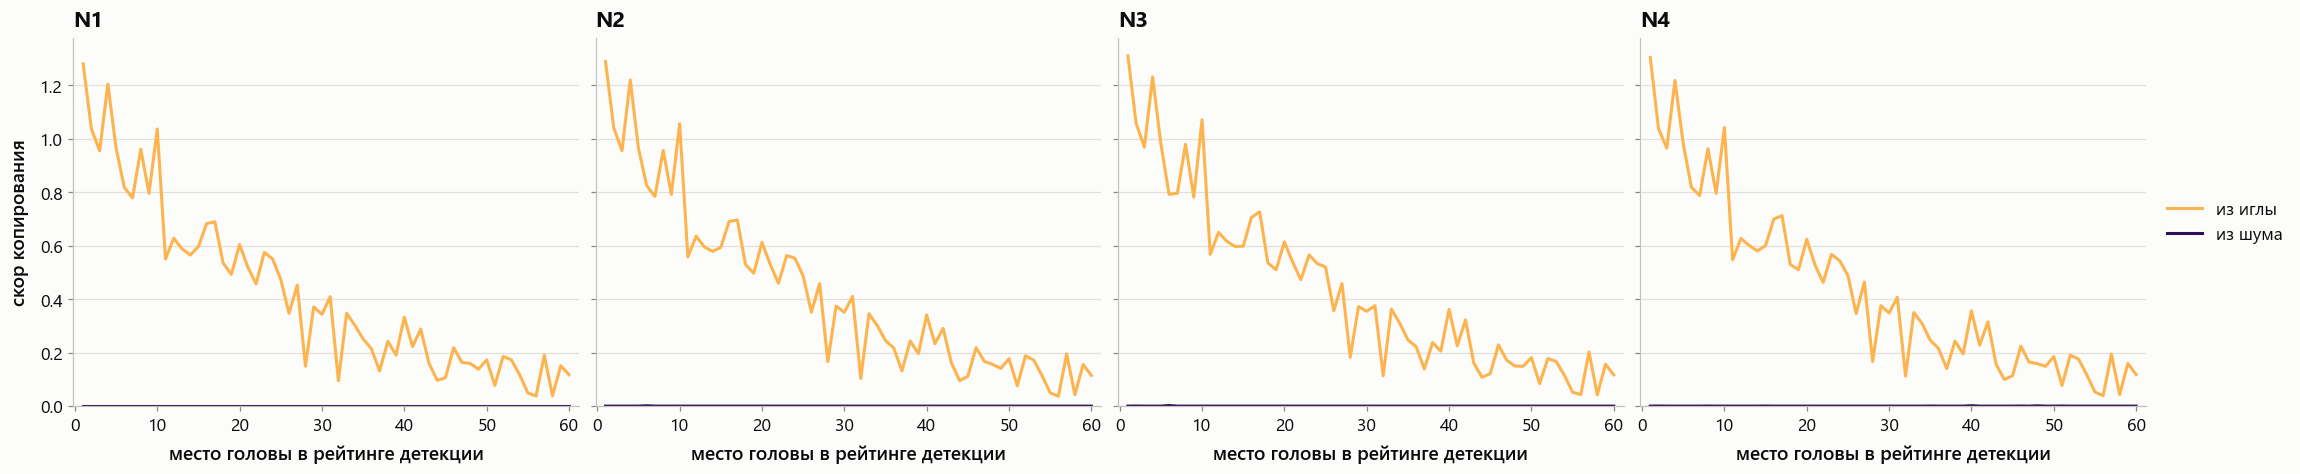

копирование из иглы (copy_sentence): среднее у лучших голов детекции


,A0,N1,N2,N3,N4
20 лучших,0.7839,0.7887,0.7939,0.8049,0.7976
40 лучших,0.5602,0.5634,0.5678,0.5758,0.5706
60 лучших,0.4210,0.4234,0.4269,0.4336,0.4298


копирование из шума (copy_competing)


,N1,N2,N3,N4
20 лучших,0.0,0.0001,0.0001,0.0001
40 лучших,0.0,0.0000,0.0001,0.0001
60 лучших,0.0,0.0000,0.0000,0.0001


доля копирования из шума в общем копировании, %


,N1,N2,N3,N4
20 лучших,0.0,0.0,0.0,0.0
40 лучших,0.0,0.0,0.0,0.0
60 лучших,0.0,0.0,0.0,0.0


In [39]:
copy_needle = hard.level_scores(heads, "copy_sentence", where=common)
copy_twin = hard.level_scores(heads, "copy_competing", where=common)

top_copy = max(float(copy_needle[level].ravel()[order[:60]].max()) for level in twin_levels)
axes = panels(len(twin_levels), 4.8, extra=1.6, sharey=True)
for ax, level in zip(axes, twin_levels):
    plots.rank_profile({"из иглы": copy_needle[level], "из шума": copy_twin[level]}, order, top=60, ylabel="скор копирования",
                       legend=ax is axes[-1], ax=ax, title=level)
    ax.set_ylim(0, top_copy * 1.05)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "N_copy_needle_vs_twin")

print("копирование из иглы (copy_sentence): среднее у лучших голов детекции")
display(hard.top_means(copy_needle, order))
print("копирование из шума (copy_competing)")
display(hard.top_means({level: copy_twin[level] for level in twin_levels}, order))
print("доля копирования из шума в общем копировании, %")
display((hard.top_means({level: copy_twin[level] for level in twin_levels}, order)
         / (hard.top_means({level: copy_twin[level] for level in twin_levels}, order) + hard.top_means({level: copy_needle[level] for level in twin_levels}, order)) * 100).round(1))

## 3.7. По семействам

Совпадает ли направление эффекта в каждом семействе: у 20 лучших голов детекции — скор копирования и избирательность по уровням.

средний скор копирования 20 лучших голов детекции


,A0,N1,N2,N3,N4
cairo,0.6670,0.6717,0.6742,0.6791,0.6760
lisbon,0.6815,0.6859,0.6886,0.6914,0.6903
oslo,0.6856,0.6898,0.6914,0.6953,0.6924


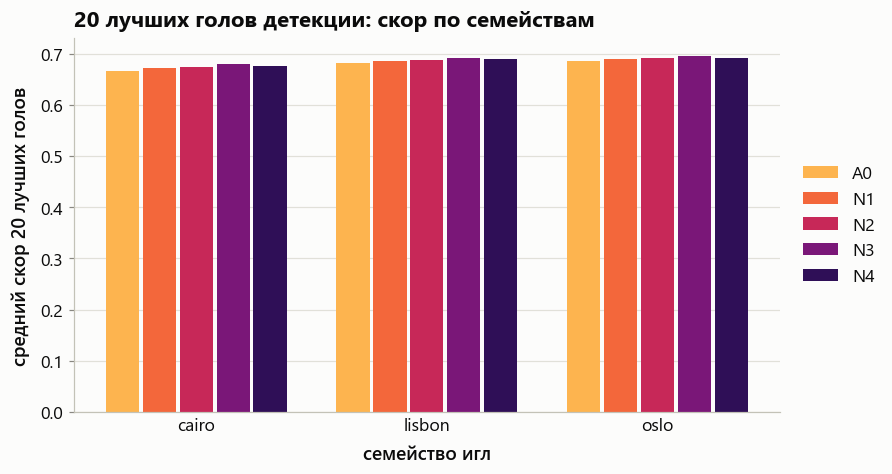

средняя избирательность 20 лучших голов детекции


,N1,N2,N3,N4
cairo,0.9935,0.9842,0.9746,0.9682
lisbon,0.9951,0.9868,0.9804,0.9765
oslo,0.9950,0.9869,0.9746,0.9745


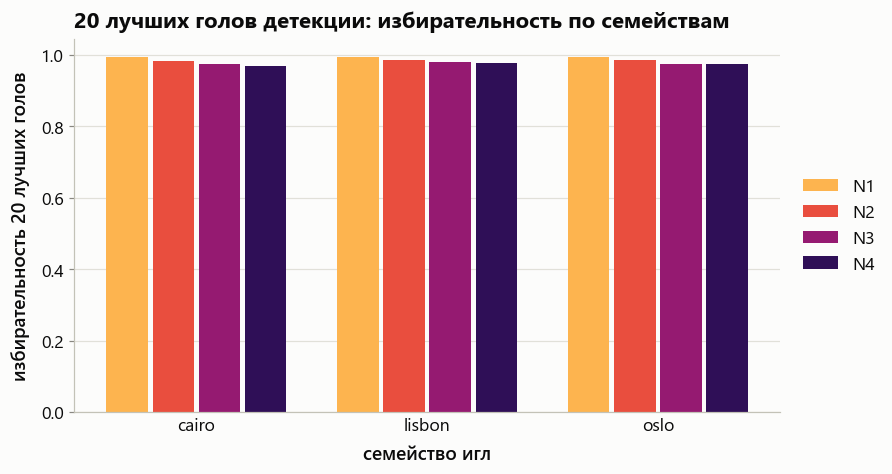

In [40]:
def family_mask(family):
    return common & (heads.samples["family"] == family).to_numpy()

family_top = pd.DataFrame({family: hard.top_means(hard.level_scores(heads, METRIC, where=family_mask(family)), order).loc["20 лучших"] for family in families}).T
print("средний скор копирования 20 лучших голов детекции")
display(family_top)
show(plots.group_bars(family_top, xlabel="семейство игл", ylabel="средний скор 20 лучших голов", title="20 лучших голов детекции: скор по семействам"), "N_family_top20")

rows = {}
for family in families:
    n = hard.level_scores(heads, "needle_sentence_mass", where=family_mask(family), levels=twin_levels)
    r = hard.level_scores(heads, "competing_max_mass", where=family_mask(family), levels=twin_levels)
    rows[family] = hard.top_means({level: hard.selectivity(n[level], r[level]) for level in twin_levels}, order).loc["20 лучших"]
family_select = pd.DataFrame(rows).T
print("средняя избирательность 20 лучших голов детекции")
display(family_select)
show(plots.group_bars(family_select, xlabel="семейство игл", ylabel="избирательность 20 лучших голов", title="20 лучших голов детекции: избирательность по семействам"), "N_family_selectivity")

## 3.8. Появляются ли новые головы

Головы, которые на уровне входят в 20 лучших по скору копирования, но в детекции стояли за пределами первых 60.

In [41]:
rows = []
for level in levels:
    for i in np.argsort(-scores[level].ravel(), kind="stable")[:20]:
        if place[int(i)] > 60:
            rows.append({"уровень": level, "голова": heads.name(i), "место в детекции": place[int(i)], "скор детекции": round(float(reference.ravel()[i]), 3),
                         **{l: round(float(scores[l].ravel()[i]), 3) for l in levels}})
pd.DataFrame(rows) if rows else print("таких голов нет")

таких голов нет
